# BreathBreak — Track 1: AFE4950 ECG/PPG preprocessing and a normal-vs-fatigue classifier

This notebook follows the **Track 1 Technical User Guide** (`Track1_Manual.pdf`), Sections 7–9: verify the export, preprocess, detect ECG beats and optical peaks, match them, estimate heart rate, and write metrics. It then extends that workflow with a simple **normal vs. fatigue** classifier.

| Manual step | What it asks | Where |
|---|---|---|
| Step 22 | Keep the original exports in a data folder; never modify them | §0 |
| Step 23 | Verify timestamped ECG + optical channels, sample counts, duration | §1 |
| Step 24 | Load with `index_col=False` (trailing delimiter) | §1 |
| Step 27–28 | Project layout; paths relative to the project | §0 |
| §9.1 / Steps 29–31 | Preprocess → R-peak candidates → optical peak candidates → ECG/PPG matches → HR → `metrics.json`, `candidate_matches.csv` | §3–§4 |
| Figure 21 | Whole-recording ECG R-peak plot | §4 |
| §9.2 | Interpretation (candidates are not clinical measurements) | §4, §8 |
| Appendix A.4 | Result summary format | §4 |

**Data:** `normal/*.csv` (label 0) and `fatigue/*.csv` (label 1). There are 5 recordings each, all TI Bio-Sensing GUI exports from the AFE4950EVM.

## 0. Setup (manual Steps 25–28)

In [1]:
import json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, balanced_accuracy_score

warnings.filterwarnings('ignore', category=RuntimeWarning); warnings.filterwarnings('ignore', category=UserWarning)
plt.rcParams.update({'figure.figsize': (14, 3.2), 'axes.grid': True, 'grid.alpha': .3, 'font.size': 9})

ROOT = Path.cwd()                                   # notebook lives in the project root (Step 28: relative paths)
CONDITIONS = {'normal': 0, 'fatigue': 1}
FS_ECG, FS_PPG = 500, 50                            # manual §1.4 reference rates
OUT = ROOT / 'outputs'                              # generated files; the source CSVs are never modified (Step 22)

files = [(cond, p) for cond in CONDITIONS for p in sorted((ROOT / cond).glob('*.csv'),
         key=lambda p: ['first', 'second', 'third', 'fourth', 'fifth'].index(p.stem.split('_')[0])
         if p.stem.split('_')[0] in ['first', 'second', 'third', 'fourth', 'fifth'] else 99)]
rec_id = lambda cond, p: f"{cond}/{p.stem}"
pd.DataFrame([(c, p.name, f'{p.stat().st_size/1e6:.1f} MB') for c, p in files], columns=['folder', 'file', 'size'])

,folder,file,size
0,normal,first_attempt.csv,4.0 MB
1,normal,second_attempt.csv,3.8 MB
2,normal,third_attempt.csv,1.2 MB
3,normal,fourth_attempt.csv,0.8 MB
4,normal,fifth_attempt.csv,0.9 MB
5,fatigue,first_attempt.csv,0.8 MB
6,fatigue,second_attempt.csv,0.9 MB
7,fatigue,third_attempt.csv,1.1 MB
8,fatigue,fourth_attempt.csv,1.0 MB
9,fatigue,fifth_attempt.csv,0.9 MB


## 1. Load and verify the export (manual Steps 23–24)

**Step 24:** every data row of the TI export ends with a trailing comma, but the header doesn't.
Without `index_col=False`, pandas treats the first column as the row index, and **every column label shifts by one**. The next cell shows the problem on one file.

In [2]:
demo = ROOT / 'fatigue' / 'first_attempt.csv'
wrong = pd.read_csv(demo).head(3)
right = pd.read_csv(demo, index_col=False).head(3)
print('WITHOUT index_col=False -> "ECG_Time" column actually holds ECG volts:')
display(wrong[['ECG_Time', 'ECG_Value']])
print('WITH index_col=False (correct):')
display(right[['ECG_Time', 'ECG_Value', 'TIA1-3_Time', 'TIA1-3_Value']])

WITHOUT index_col=False -> "ECG_Time" column actually holds ECG volts:


,ECG_Time,ECG_Value
0.0000,-0.003029,0.000
0.0005,-0.003714,0.002
0.0010,-0.004451,0.004


WITH index_col=False (correct):


,ECG_Time,ECG_Value,TIA1-3_Time,TIA1-3_Value
0,0.000,-0.003029,0.00,0.000066
1,0.002,-0.003714,0.02,0.000077
2,0.004,-0.004451,0.04,0.000093


In [3]:
CHANNELS = ['AFE_REG_6D', 'ECG', 'ECG_RAW', 'TIA1-3', 'TIA1-3_RAW']

def load_recording(path):
    df = pd.read_csv(path, index_col=False)
    return {ch: df[[f'{ch}_Time', f'{ch}_Value']].dropna().set_axis(['t', 'v'], axis=1).reset_index(drop=True)
            for ch in CHANNELS}

recs = {rec_id(c, p): dict(cond=c, label=CONDITIONS[c], path=p, ch=load_recording(p)) for c, p in files}

rows = []
for rid, r in recs.items():
    e, o = r['ch']['ECG'], r['ch']['TIA1-3']
    rows.append(dict(recording=rid, ecg_samples=len(e), optical_samples=len(o),
                     ecg_fs=round(1/np.median(np.diff(e.t)), 1), optical_fs=round(1/np.median(np.diff(o.t)), 1),
                     start_s=e.t.iloc[0], end_s=round(e.t.iloc[-1], 2),
                     uniform_time=bool(np.allclose(np.diff(e.t), 1/FS_ECG) and np.allclose(np.diff(o.t), 1/FS_PPG)),
                     ratio_10to1=len(e) == 10*len(o),
                     nan_in_channels=int(e.v.isna().sum() + o.v.isna().sum())))
verify = pd.DataFrame(rows).set_index('recording')
assert (verify.ecg_fs == FS_ECG).all() and (verify.optical_fs == FS_PPG).all()
verify

,ecg_samples,optical_samples,ecg_fs,optical_fs,start_s,end_s,uniform_time,ratio_10to1,nan_in_channels
recording,,,,,,,,,
normal/first_attempt,69770,6977,500.0,50.0,0.0,139.54,True,True,0
normal/second_attempt,66470,6647,500.0,50.0,0.0,132.94,True,True,0
normal/third_attempt,20650,2065,500.0,50.0,0.0,41.30,True,True,0
normal/fourth_attempt,14550,1455,500.0,50.0,0.0,29.10,True,True,0
normal/fifth_attempt,15840,1584,500.0,50.0,0.0,31.68,True,True,0
fatigue/first_attempt,13790,1379,500.0,50.0,0.0,27.58,True,True,0
fatigue/second_attempt,16440,1644,500.0,50.0,0.0,32.88,True,True,0
fatigue/third_attempt,18830,1883,500.0,50.0,0.0,37.66,True,True,0
fatigue/fourth_attempt,17530,1753,500.0,50.0,0.0,35.06,True,True,0


**Check:** every file has ECG at **500 Hz** and optical (TIA1-3) at **50 Hz**, evenly spaced time stamps from 0 s, and the same **10:1** sample ratio as the manual's reference (13,740 : 1,374). This matches manual §1.4.

## 2. Signal quality check (before preprocessing)

In [4]:
COUNTS_PER_V = 2**23 / 4.8          # 24-bit two's complement, ±1.2 V full scale × gain

def signed24(raw):
    return np.where(raw >= 2**23, raw - 2**24, raw)

def hum_ratio(x, fs=FS_ECG):
    f, P = signal.welch(x, fs, nperseg=min(4096, len(x)))
    hum = (f > 59) & (f < 61)
    return P[hum].sum() / P[(f >= 5) & (f < 40) & ~hum].sum()

rows = []
for rid, r in recs.items():
    ch = r['ch']; ecg = ch['ECG'].v.values; opt = ch['TIA1-3'].v.values
    m = np.abs(ecg) > 1e-3
    rows.append(dict(recording=rid, duration_s=round(len(ecg)/FS_ECG, 1),
                     ecg_counts_per_V=round(np.median(signed24(ch['ECG_RAW'].v.values)[m] / ecg[m])),
                     ecg_pp_mV=round(1000*np.ptp(ecg), 1), ecg_saturated_pct=round(100*np.mean(np.abs(ecg) > 1.19), 2),
                     hum60_ratio=round(hum_ratio(ecg), 2),
                     optical_raw_counts=f"{ch['TIA1-3_RAW'].v.min():.0f}–{ch['TIA1-3_RAW'].v.max():.0f}",
                     optical_pp_mV=round(1000*np.ptp(opt), 3),
                     reg6d=ch['AFE_REG_6D'].v.unique().tolist()))
quality = pd.DataFrame(rows).set_index('recording')
quality['optical_present'] = quality.optical_pp_mV > 5          # empty channel ≈ 0.1 mV of ADC noise
quality

,duration_s,ecg_counts_per_V,ecg_pp_mV,ecg_saturated_pct,hum60_ratio,optical_raw_counts,optical_pp_mV,reg6d,optical_present
recording,,,,,,,,,
normal/first_attempt,139.5,1747627,68.2,0.0,0.45,1258042–1485752,130.297,[10.0],True
normal/second_attempt,132.9,1747627,79.8,0.0,1.45,518–16777129,1422.872,[10.0],True
normal/third_attempt,41.3,1747627,82.0,0.0,1.53,25–249,0.128,[10.0],False
normal/fourth_attempt,29.1,1747627,90.8,0.0,1.17,33–250,0.124,[10.0],False
normal/fifth_attempt,31.7,1747627,87.5,0.0,0.79,4–244,0.137,[10.0],False
fatigue/first_attempt,27.6,1747627,59.5,0.0,0.09,24–247,0.128,[10.0],False
fatigue/second_attempt,32.9,1747627,126.7,0.0,0.21,8–235,0.130,[10.0],False
fatigue/third_attempt,37.7,1747627,138.5,0.0,7.15,1–261,0.149,[10.0],False
fatigue/fourth_attempt,35.1,1747627,209.9,0.0,9.53,32–252,0.126,[10.0],False


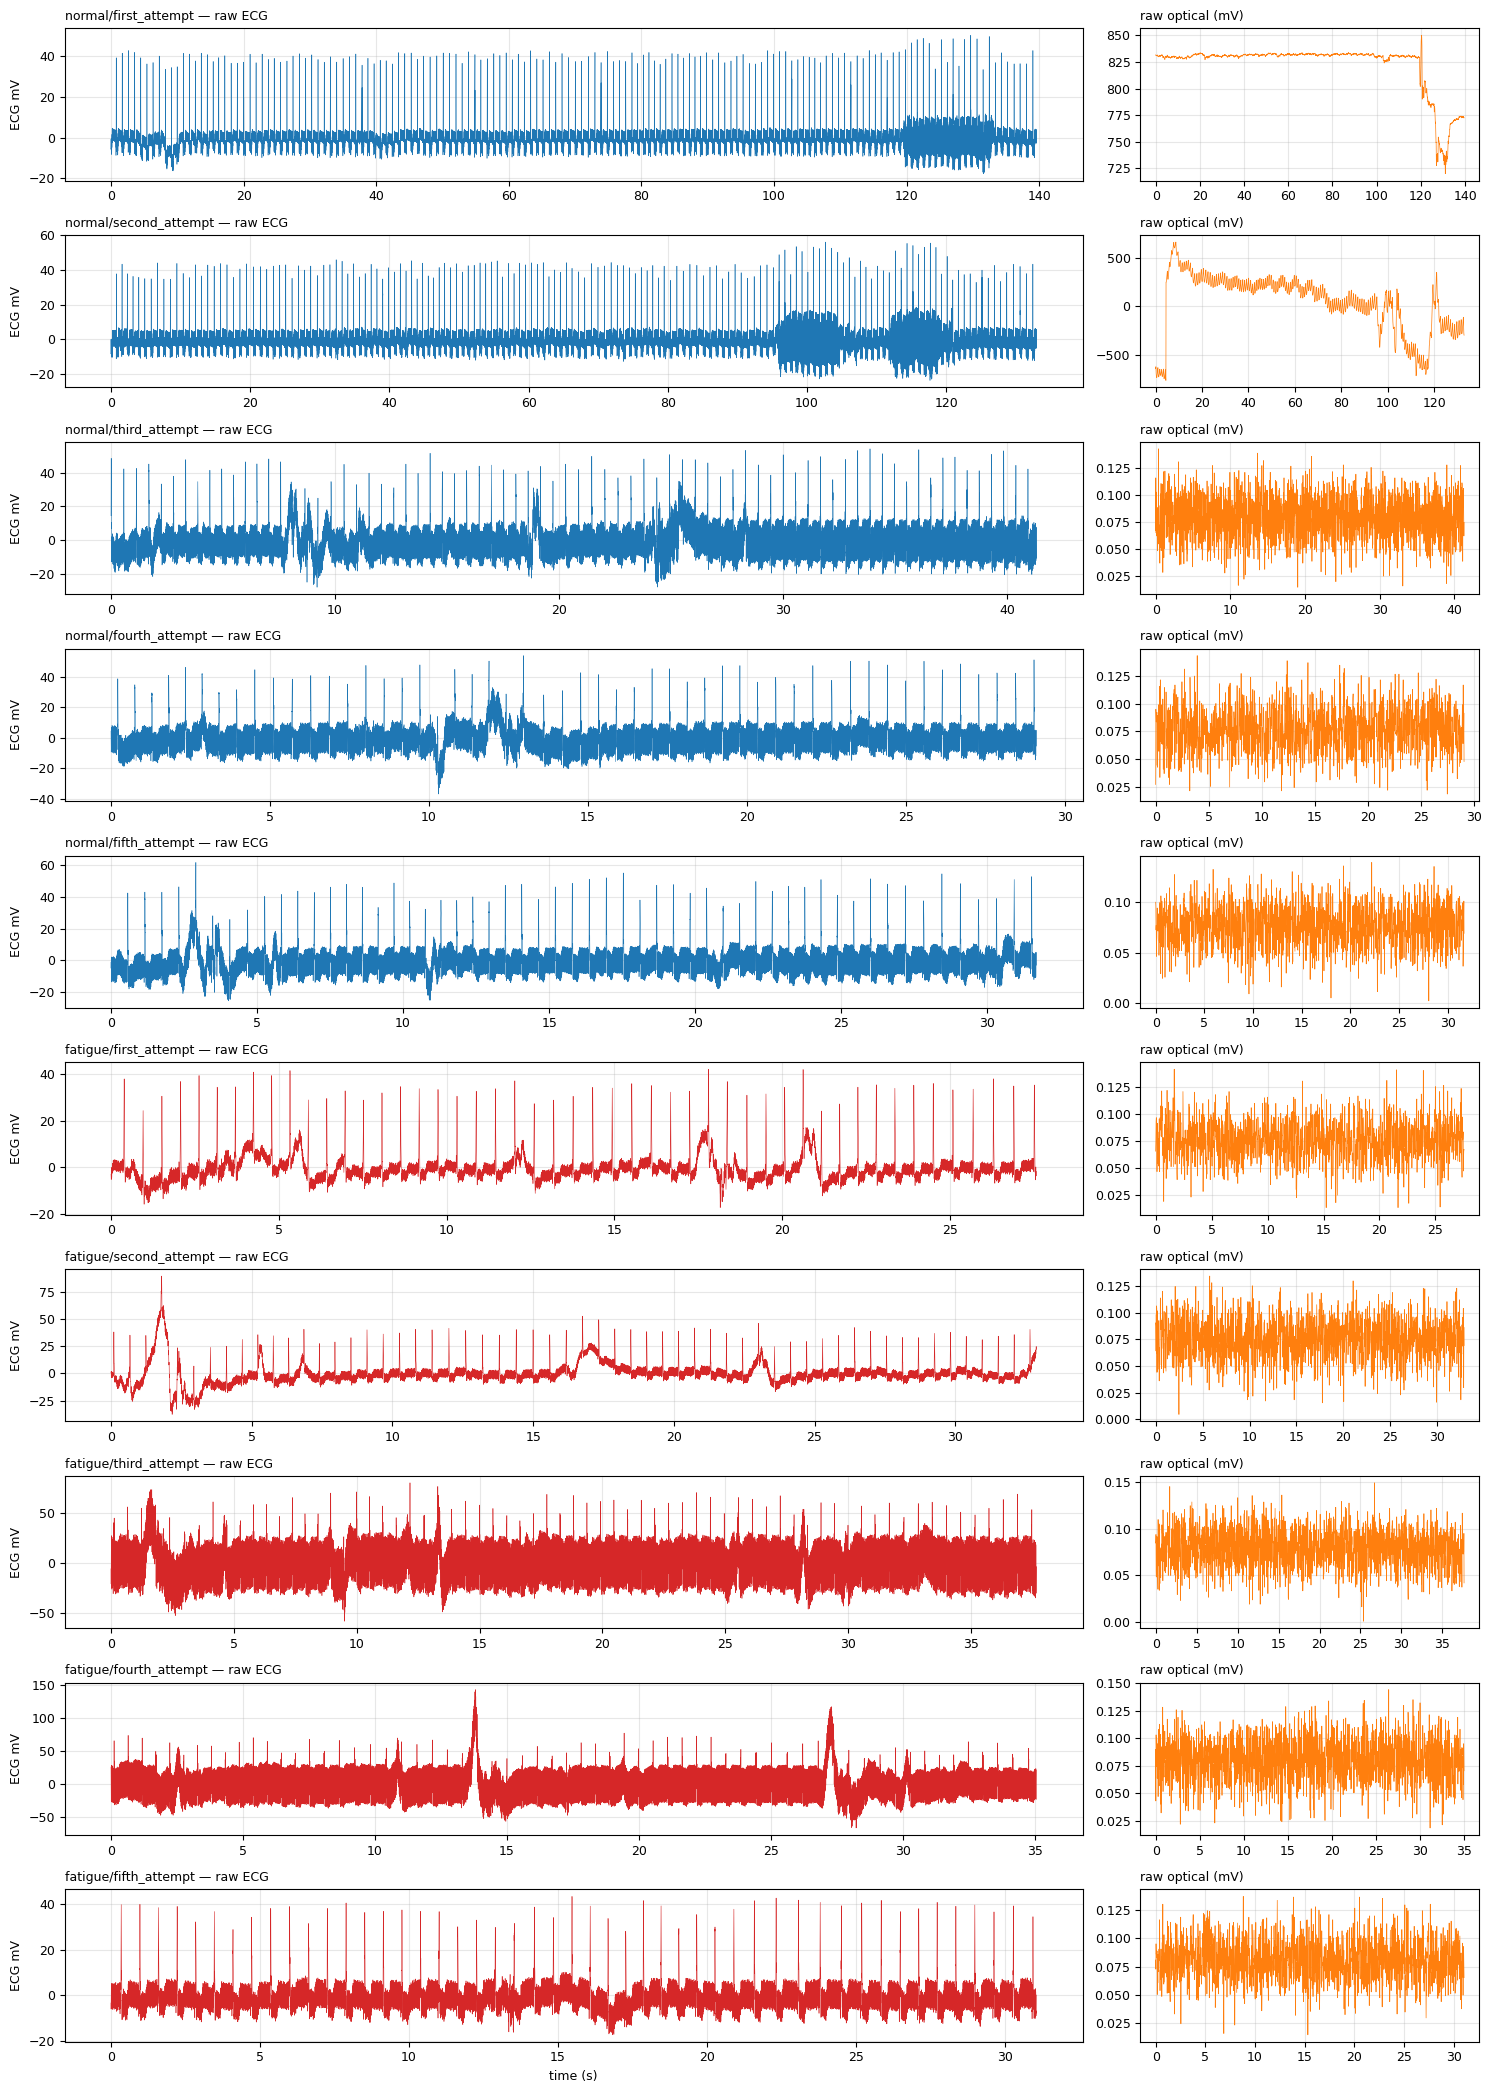

In [5]:
fig, ax = plt.subplots(len(recs), 2, figsize=(15, 2.1*len(recs)), gridspec_kw={'width_ratios': [3, 1]})
for i, (rid, r) in enumerate(recs.items()):
    e, o = r['ch']['ECG'], r['ch']['TIA1-3']
    ax[i, 0].plot(e.t, 1000*e.v, lw=.4, c='C3' if r['label'] else 'C0'); ax[i, 0].set_ylabel('ECG mV')
    ax[i, 0].set_title(f'{rid} — raw ECG', fontsize=9, loc='left')
    ax[i, 1].plot(o.t, 1000*o.v, lw=.5, c='C1'); ax[i, 1].set_title('raw optical (mV)', fontsize=9, loc='left')
ax[-1, 0].set_xlabel('time (s)'); plt.tight_layout(); plt.show()

**Findings**
- **Format:** all 10 files pass the manual's export checks. `ECG_RAW` maps to `ECG_Value` at exactly 1,747,627 counts/V (24-bit two's complement), and `AFE_REG_6D` is a constant register read-back (10) with no signal. No ECG sample saturates (±1.2 V).
- **Optical channel empty in 8 of 10 recordings.** Every file except `normal/first` and `normal/second` has optical values of only 1–261 raw counts (≈ 0.13 mV peak-to-peak), which is ADC noise. The PPG sensor wasn't connected or the LED was off. **Only ECG can be used to compare normal and fatigue.**
- **Mains (60 Hz) interference** is very strong in `fatigue/third` (7×) and `fatigue/fourth` (9.5×) and moderate in several others. Step P3 removes it.
- **Motion and baseline wander:** the larger ECG peak-to-peak values of `fatigue/second–fourth` (127–210 mV, against about 60–90 mV elsewhere) come from motion spikes, not bigger heartbeats. Steps P2 and P5 handle these.
- **Two different recording setups:**
  - `normal/first` and `normal/second`: 133–140 s long, optical working, resting HR about 65–70 bpm. `normal/second` is the same recording as the earlier dataset's `user1`.
  - Every other file: 28–41 s long, optical off, HR about 95–110 bpm. This matches the manual's ~27.5 s reference capture.
  This split matters for the classifier (§5, §7).


## 3. Preprocessing, step by step

The steps are shown on one recording with every common problem: `fatigue/fourth_attempt.csv`, which has strong 60 Hz mains noise, baseline wander and a motion artifact. The same functions are then applied to every recording.

| Step | Operation | Why |
|---|---|---|
| P1 | Remove DC offset, convert to mV | The AFE output sits on an electrode offset |
| P2 | High-pass 0.5 Hz | Removes **baseline wander** from breathing and movement |
| P3 | 60 Hz notch (Q = 30) | Removes **mains interference** picked up by the leads |
| P4 | Low-pass 40 Hz | Removes **muscle (EMG) and high-frequency noise** while keeping the QRS shape |
| P5 | Artifact mask | Flags saturation (±1.2 V) and motion spikes so they can't create false beats |
| P6 | Pan–Tompkins R-peak detection | Finds each heartbeat (manual: "ECG beat candidates") |
| P7 | RR-interval cleaning | Removes missed or extra beats before HR/HRV |
| P8 | Optical (PPG) processing | Band-pass 0.5–4 Hz → optical peak candidates → ECG/PPG matching |
| P9 | Windowing | 20 s windows every 5 s → features for the classifier |

All filters are zero-phase Butterworth (`filtfilt`), so they add **no time delay**. That matters because R-peak times are used to compute intervals.

In [6]:
def butter(x, fc, kind, fs, order=2):
    b, a = signal.butter(order, fc, btype=kind, fs=fs)
    return signal.filtfilt(b, a, x)

def psd(x, fs=FS_ECG):
    f, P = signal.welch(x, fs, nperseg=min(4096, len(x)))
    return f, 10*np.log10(P + 1e-20)

EX = 'fatigue/fourth_attempt'
ecg_raw = recs[EX]['ch']['ECG'].v.values
t_ecg = np.arange(len(ecg_raw)) / FS_ECG
zoom = (t_ecg > 9) & (t_ecg < 13)

def show_step(before, after, title, note=''):
    fig, ax = plt.subplots(1, 2, figsize=(15, 3), gridspec_kw={'width_ratios': [2.2, 1]})
    ax[0].plot(t_ecg[zoom], before[zoom], c='grey', lw=.8, label='before')
    ax[0].plot(t_ecg[zoom], after[zoom], c='C0', lw=1, label='after'); ax[0].legend(loc='upper right')
    ax[0].set(title=f'{title} — time domain (9–13 s)', xlabel='time (s)', ylabel='mV')
    for x, c, l in ((before, 'grey', 'before'), (after, 'C0', 'after')):
        f, P = psd(x); ax[1].plot(f, P, c=c, lw=.8, label=l)
    ax[1].set(title='power spectrum', xlabel='Hz', ylabel='dB', xlim=(0, 130)); ax[1].legend()
    plt.tight_layout(); plt.show()
    if note: print(note)

### P1 — Remove DC offset and convert to mV
`ECG_Value` is in volts and includes the electrode's DC offset. Subtracting the median centres the signal, and multiplying by 1000 gives mV, the unit used in the manual's Figure 21.

In [7]:
p1 = 1000 * (ecg_raw - np.median(ecg_raw))
print(f'DC offset removed: {1000*np.median(ecg_raw):.3f} mV; peak-to-peak {np.ptp(p1):.1f} mV')

DC offset removed: -2.630 mV; peak-to-peak 209.9 mV


### P2 — High-pass 0.5 Hz (baseline wander)
Breathing and body movement shift the ECG baseline slowly (< 0.5 Hz). A 0.5 Hz high-pass removes that drift but keeps the ECG waveform, whose lowest important content (the T-wave) is about 0.7 Hz or higher.

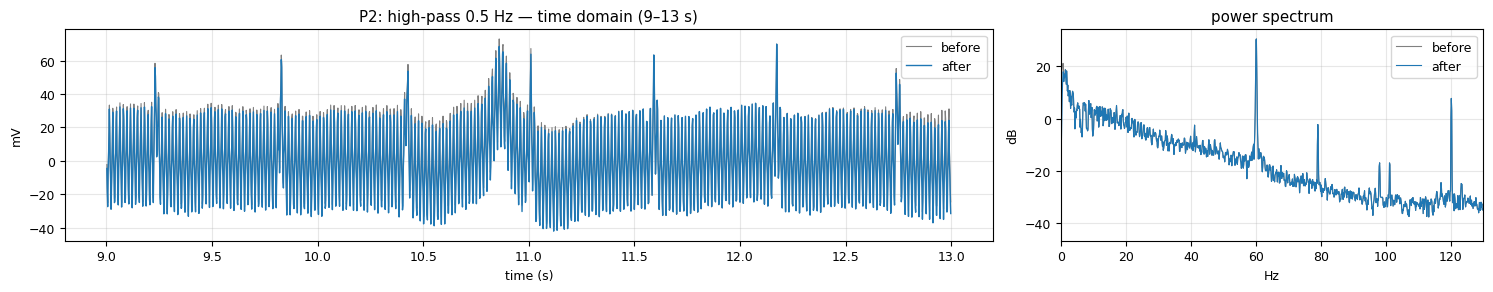

Slow drift removed; the spectrum below 0.5 Hz drops.


In [8]:
p2 = butter(p1, 0.5, 'highpass', FS_ECG)
show_step(p1, p2, 'P2: high-pass 0.5 Hz', 'Slow drift removed; the spectrum below 0.5 Hz drops.')

### P3 — 60 Hz notch (mains interference)
This recording has a strong 60 Hz sinusoid from the power line, visible as the "thick" trace and a sharp spectral spike. A narrow IIR notch (Q = 30, about 2 Hz wide) removes it while leaving the rest of the spectrum untouched.

60 Hz power relative to ECG band: before 9.53 -> after 0.003


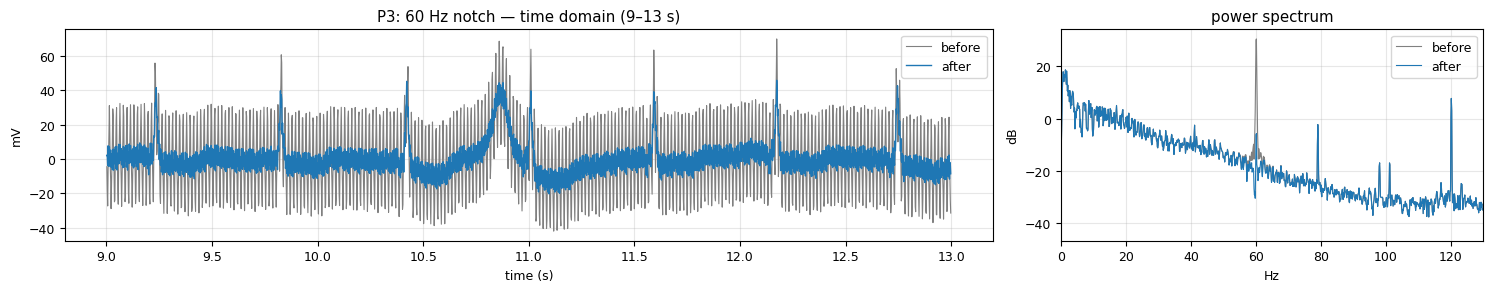

In [9]:
b, a = signal.iirnotch(60, 30, FS_ECG)
p3 = signal.filtfilt(b, a, p2)
print(f'60 Hz power relative to ECG band: before {hum_ratio(p2):.2f} -> after {hum_ratio(p3):.3f}')
show_step(p2, p3, 'P3: 60 Hz notch')

### P4 — Low-pass 40 Hz (muscle / high-frequency noise)
Muscle activity (EMG) and amplifier noise sit mostly above 40 Hz. The QRS complex has most of its energy below 40 Hz, so a 40 Hz low-pass smooths the trace without blunting the R-peaks. This also removes the 120 and 180 Hz mains harmonics.

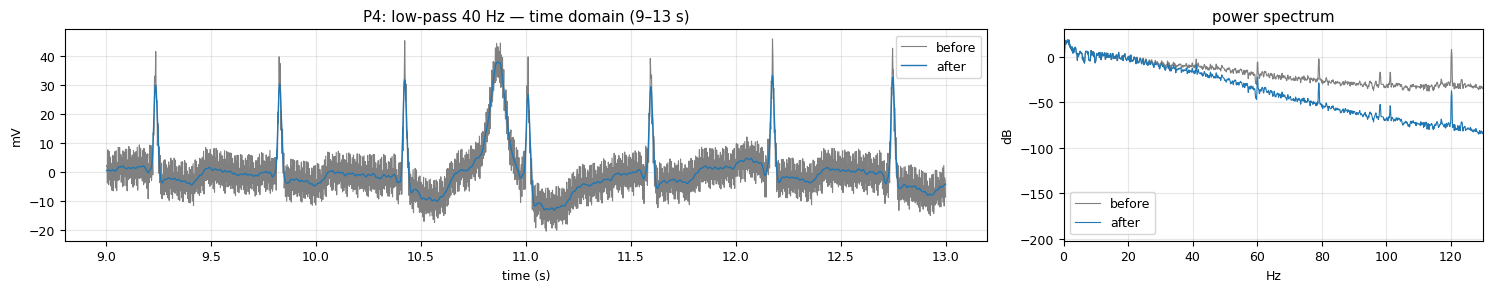

Result = clean ECG used for all further steps.


In [10]:
p4 = butter(p3, 40, 'lowpass', FS_ECG)
show_step(p3, p4, 'P4: low-pass 40 Hz', 'Result = clean ECG used for all further steps.')

def clean_ecg(ecg_v):
    # P1–P4 combined: volts in -> clean ECG in mV
    x = 1000 * (ecg_v - np.median(ecg_v))
    x = butter(x, 0.5, 'highpass', FS_ECG)
    b, a = signal.iirnotch(60, 30, FS_ECG); x = signal.filtfilt(b, a, x)
    return butter(x, 40, 'lowpass', FS_ECG)

assert np.allclose(clean_ecg(ecg_raw), p4)

### P5 — Artifact mask (saturation and motion)
Filtering can't fix samples where the amplifier **saturated** (|ECG| ≥ 1.19 V), or where the person **moved** and caused a spike much larger than a heartbeat. Instead those parts are **masked**:
1. Split the clean ECG into 1 s blocks and take each block's peak |amplitude|.
2. The median block peak is the typical R-peak height. Any block whose peak is more than **2×** that is a motion artifact. (R-peak heights vary by only about ±25 % within a recording, so 2× is clearly abnormal.)
3. Add saturated samples, then extend the mask by ±0.5 s.

Masked samples are ignored for beat detection and features.

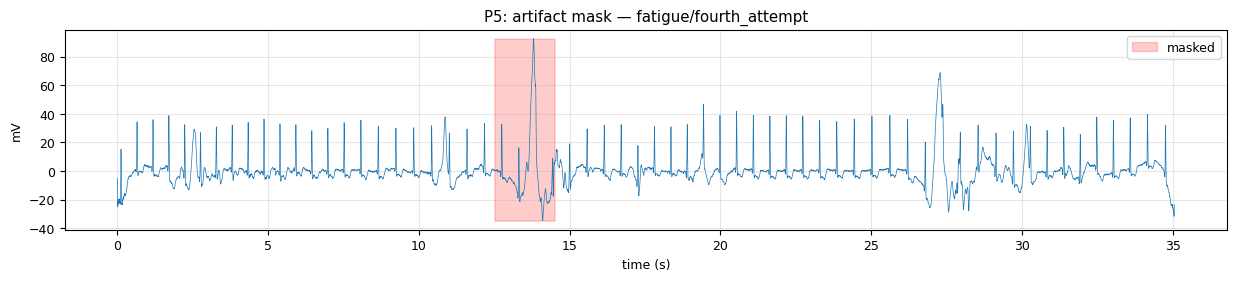

masked: 5.7% of samples


In [11]:
def artifact_mask(ecg_v, ecg_clean, k=2.0, fs=FS_ECG):
    sec = np.arange(len(ecg_clean)) // fs
    peak = pd.Series(np.abs(ecg_clean)).groupby(sec).max()
    bad = np.isin(sec, peak.index[peak > k * peak.median()]) | (np.abs(ecg_v) > 1.19)
    return np.convolve(bad, np.ones(fs), 'same') > 0

mask_ex = artifact_mask(ecg_raw, p4)
fig, ax = plt.subplots(figsize=(15, 2.6))
ax.plot(t_ecg, p4, lw=.5)
ax.fill_between(t_ecg, p4.min(), p4.max(), where=mask_ex, color='red', alpha=.2, label='masked')
ax.set(title=f'P5: artifact mask — {EX}', xlabel='time (s)', ylabel='mV'); ax.legend(); plt.show()
print(f'masked: {mask_ex.mean():.1%} of samples')

### P6 — R-peak detection (Pan–Tompkins)
This is the classic Pan & Tompkins (1985) QRS detector. Each stage is plotted below:
1. **Band-pass 5–20 Hz:** keeps the QRS energy and suppresses P/T-waves and residual drift.
2. **Derivative:** emphasises the steep QRS slopes.
3. **Squaring:** makes everything positive and boosts large slopes.
4. **Moving-window integration (120 ms):** gives one smooth hump per QRS.
5. **Peak picking:** humps above 30 % of the 99th percentile, at least 330 ms apart (max 180 bpm).
6. **Refine:** find the lead's dominant R polarity (sign of the median detected peak), then move each detection to the largest deflection *in that direction* within ±60 ms, the true R-peak.
7. **Validate:** keep a beat only if its R amplitude is **0.5–1.6×** the median R amplitude. Motion spikes are taller, or point the wrong way, and very small bumps are T-waves or noise.

Peaks inside masked regions are dropped. The survivors are the manual's **"ECG beat candidates"**.

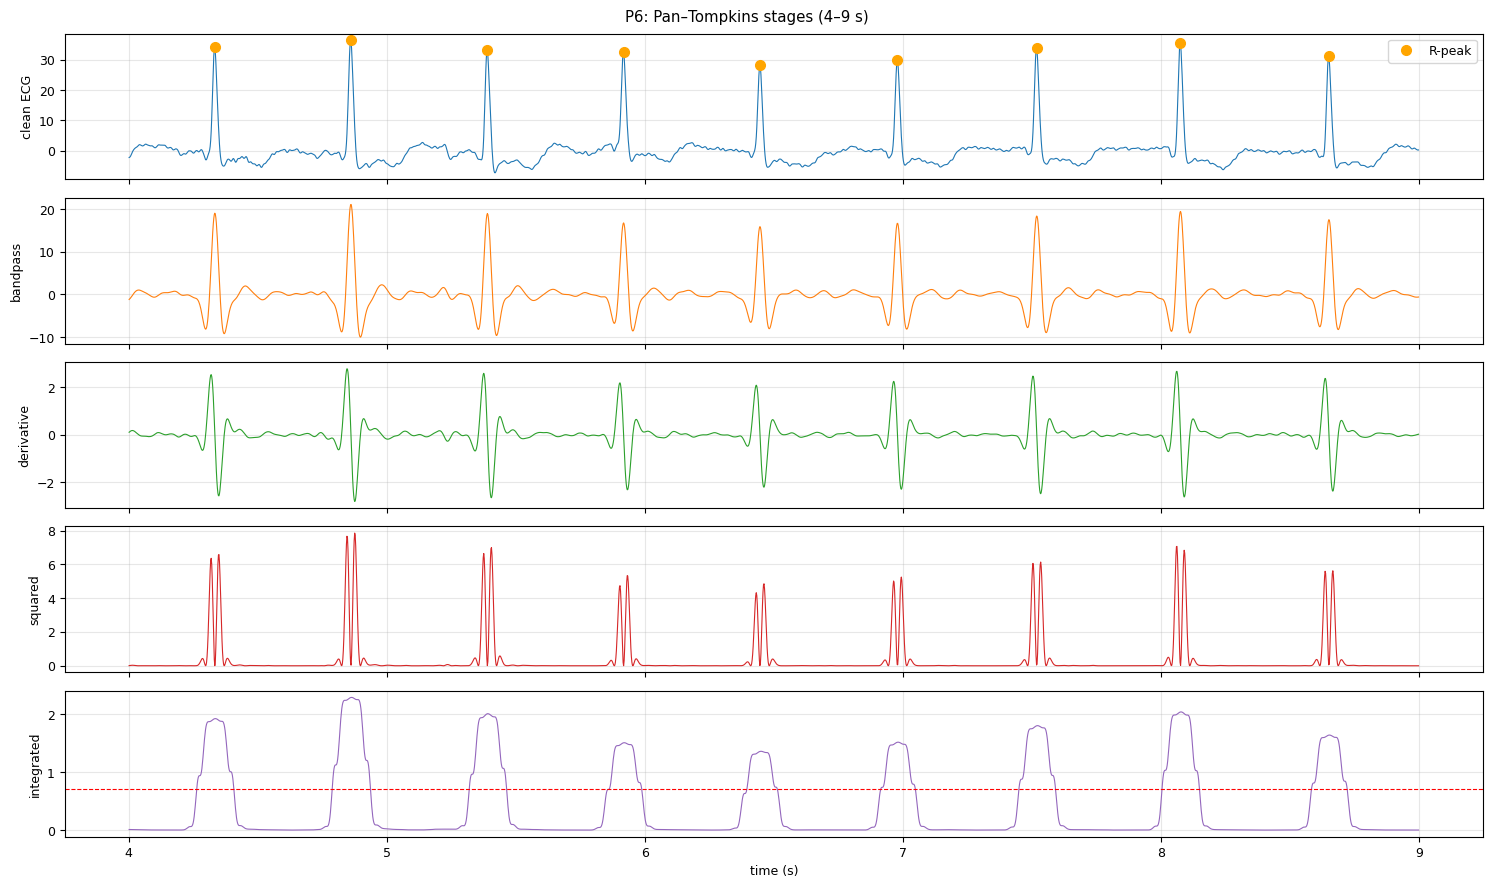

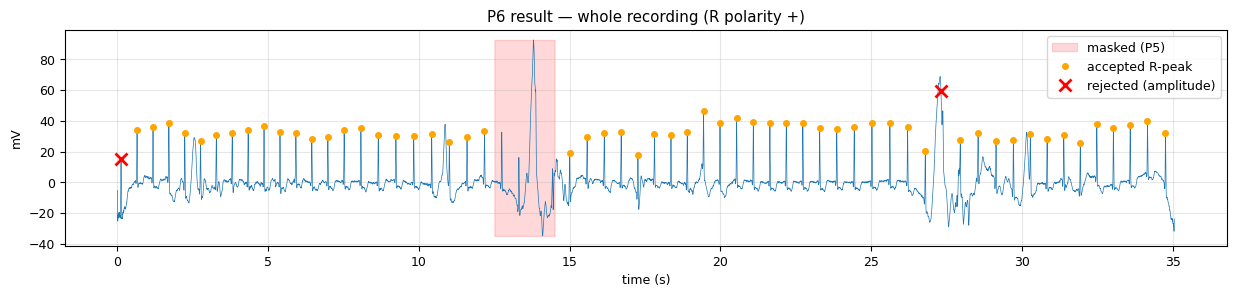

57 R-peaks accepted, 2 rejected by amplitude validation in fatigue/fourth_attempt


In [12]:
def pan_tompkins(ecg_clean, bad, fs=FS_ECG, return_stages=False):
    x = np.where(bad, 0, ecg_clean)
    bp = butter(x, [5, 20], 'bandpass', fs)
    der = np.gradient(bp)
    sq = der**2
    w = int(0.12*fs); mwi = np.convolve(sq, np.ones(w)/w, 'same')
    ref = mwi[~bad] if (~bad).any() else mwi
    pk, _ = signal.find_peaks(mwi, distance=int(0.33*fs), height=0.3*np.percentile(ref, 99))
    hw = int(0.06*fs)
    pk = np.array([p for p in pk if hw <= p < len(x)-hw], int)
    absmax = np.array([p - hw + np.argmax(np.abs(ecg_clean[p-hw:p+hw])) for p in pk], int)
    pol = np.sign(np.median(ecg_clean[absmax])) if len(pk) else 1.0          # dominant R polarity of this lead
    pk = np.array([p - hw + np.argmax(pol * ecg_clean[p-hw:p+hw]) for p in pk], int)
    pk = pk[~bad[pk]] if len(pk) else pk
    amp = pol * ecg_clean[pk]
    med = np.median(amp) if len(pk) else 0
    keep = (amp >= 0.5 * med) & (amp <= 1.6 * med)                        # amplitude validation
    rejected = pk[~keep]; pk = pk[keep]
    stages = dict(bandpass=bp, derivative=der, squared=sq, integrated=mwi, rejected=rejected, polarity=pol)
    return (pk, stages) if return_stages else pk

rp_ex, stages = pan_tompkins(p4, mask_ex, return_stages=True)
rejected_ex = stages.pop('rejected'); pol_ex = stages.pop('polarity')
z = (t_ecg > 4) & (t_ecg < 9)
fig, ax = plt.subplots(5, 1, figsize=(15, 9), sharex=True)
ax[0].plot(t_ecg[z], p4[z], lw=.8); ax[0].set_ylabel('clean ECG')
for i, (k, v) in enumerate(stages.items(), 1):
    ax[i].plot(t_ecg[z], v[z], lw=.8, c=f'C{i}'); ax[i].set_ylabel(k)
r = rp_ex[(t_ecg[rp_ex] > 4) & (t_ecg[rp_ex] < 9)]
ax[0].plot(t_ecg[r], p4[r], 'o', c='orange', ms=7, label='R-peak'); ax[0].legend(loc='upper right')
ax[4].axhline(0.3*np.percentile(stages['integrated'][~mask_ex], 99), ls='--', c='r', lw=.8)
ax[-1].set_xlabel('time (s)'); fig.suptitle('P6: Pan–Tompkins stages (4–9 s)'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(15, 2.8))
ax.plot(t_ecg, p4, lw=.5)
ax.fill_between(t_ecg, p4.min(), p4.max(), where=mask_ex, color='red', alpha=.15, label='masked (P5)')
ax.plot(t_ecg[rp_ex], p4[rp_ex], 'o', c='orange', ms=4, label='accepted R-peak')
ax.plot(t_ecg[rejected_ex], p4[rejected_ex], 'x', c='red', ms=9, mew=2, label='rejected (amplitude)')
ax.set(title=f'P6 result — whole recording (R polarity {"+" if pol_ex > 0 else "−"})', xlabel='time (s)', ylabel='mV')
ax.legend(loc='upper right'); plt.show()
print(f'{len(rp_ex)} R-peaks accepted, {len(rejected_ex)} rejected by amplitude validation in {EX}')

### P7 — RR intervals and cleaning
RR interval = time between consecutive R-peaks. Before computing HR/HRV, intervals are rejected if they are:
- **outside 0.33–1.5 s** (40–180 bpm, physiologically implausible at rest), or
- **more than 20 % from the median of the 5 surrounding beats**, which usually means a missed or extra beat or an ectopic beat.

Intervals that span a masked region are also rejected, since a beat there may have been hidden.

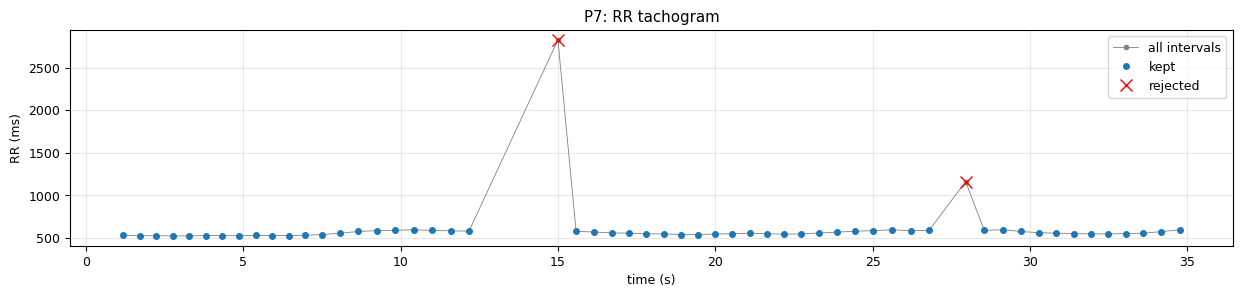

54 of 56 RR intervals kept; HR = 107.5 bpm


In [13]:
def clean_rr(t_peaks, bad_t=None, tol=0.2):
    rr = np.diff(t_peaks); t = t_peaks[1:]
    ok = (rr > 0.33) & (rr < 1.5)
    if bad_t is not None:                                   # interval overlaps a masked span
        ok &= ~np.array([bad_t[int(a*FS_ECG):int(b*FS_ECG)+1].any() for a, b in zip(t_peaks[:-1], t_peaks[1:])])
    med = pd.Series(np.where(ok, rr, np.nan)).rolling(5, center=True, min_periods=1).median().values
    ok &= np.abs(rr - med) <= tol * med
    return t, rr, ok

t_rr_ex, rr_ex, ok_ex = clean_rr(t_ecg[rp_ex], mask_ex)
fig, ax = plt.subplots(figsize=(15, 2.8))
ax.plot(t_rr_ex, 1000*rr_ex, '.-', c='grey', lw=.6, label='all intervals')
ax.plot(t_rr_ex[ok_ex], 1000*rr_ex[ok_ex], 'o', c='C0', ms=4, label='kept')
ax.plot(t_rr_ex[~ok_ex], 1000*rr_ex[~ok_ex], 'x', c='red', ms=8, label='rejected')
ax.set(title='P7: RR tachogram', xlabel='time (s)', ylabel='RR (ms)'); ax.legend(); plt.show()
print(f'{ok_ex.sum()} of {len(rr_ex)} RR intervals kept; HR = {60/rr_ex[ok_ex].mean():.1f} bpm')

### P7b — Trim the unstable start and end
The first and last seconds of a capture are often unreliable. Electrodes are still settling, the person is still moving after pressing *Start/Stop Capture*, and zero-phase filters have edge transients. Each 1 s block is scored as **unstable** if:
- the **baseline drifts** (range of the < 1 Hz component) by more than **30 %** of the median R-peak height, or
- its largest deflection is **> 1.6×** (spike) or **< 0.5×** (signal drop-out) the median R-peak height.

**Trimming rule:** always cut at least **2 s** at each end. Then keep moving the start forward (and the end back) while any of the next **3 s** is unstable. The analysis keeps only the stable middle part. Unstable seconds *inside* the kept part are left to the P5 mask and the P6/P7 beat checks.

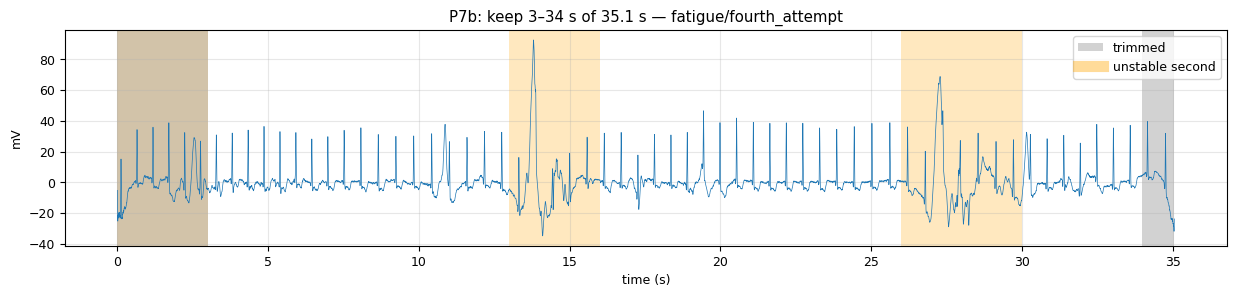

In [14]:
TRIM_MIN_S, STABLE_RUN_S = 2, 3

def unstable_blocks(ecg_v, ecg_clean, rpeaks):
    ecg_mv = 1000 * (ecg_v - np.median(ecg_v))
    sec = np.arange(len(ecg_mv)) // FS_ECG
    drift = pd.Series(butter(ecg_mv, 1.0, 'lowpass', FS_ECG)).groupby(sec).agg(np.ptp).values
    peak = pd.Series(np.abs(ecg_clean)).groupby(sec).max().values
    r_amp = np.median(np.abs(ecg_clean[rpeaks]))
    return (drift > 0.3 * r_amp) | (peak > 1.6 * r_amp) | (peak < 0.5 * r_amp)

def stable_range(bad):
    n, s, e = len(bad), TRIM_MIN_S, len(bad) - TRIM_MIN_S
    while s < e and bad[s:s + STABLE_RUN_S].any(): s += 1
    while e > s and bad[e - STABLE_RUN_S:e].any(): e -= 1
    return float(s), float(e)

bad_ex = unstable_blocks(ecg_raw, p4, rp_ex)
keep_ex = stable_range(bad_ex)
fig, ax = plt.subplots(figsize=(15, 2.8))
ax.plot(t_ecg, p4, lw=.5)
for i, b in enumerate(bad_ex):
    if b: ax.axvspan(i, i + 1, color='orange', alpha=.25, lw=0)
ax.axvspan(0, keep_ex[0], color='grey', alpha=.35, lw=0, label='trimmed'); ax.axvspan(keep_ex[1], t_ecg[-1], color='grey', alpha=.35, lw=0)
ax.plot([], [], c='orange', alpha=.4, lw=8, label='unstable second')
ax.set(title=f'P7b: keep {keep_ex[0]:.0f}–{keep_ex[1]:.0f} s of {t_ecg[-1]:.1f} s — {EX}', xlabel='time (s)', ylabel='mV'); ax.legend(loc='upper right')
plt.show()

### P8 — Optical (PPG) channel
Manual §9.1 also detects **optical peak candidates** and pairs them with ECG beats. Processing:
1. **Presence check:** in a working optical channel the TIA output varies by tens to hundreds of mV. A disconnected sensor or LED that's off leaves only ADC noise of about 0.1 mV (1–260 raw counts).
2. Band-pass **0.5–4 Hz** (30–240 bpm pulse range), then invert, because blood volume rises on each pulse and the transmitted light falls.
3. Peak picking: at least 330 ms apart, prominence ≥ 0.3 SD.
4. **Matching:** each ECG R-peak is paired with the first unused optical peak **0.10–0.80 s later** (pulse-arrival window).

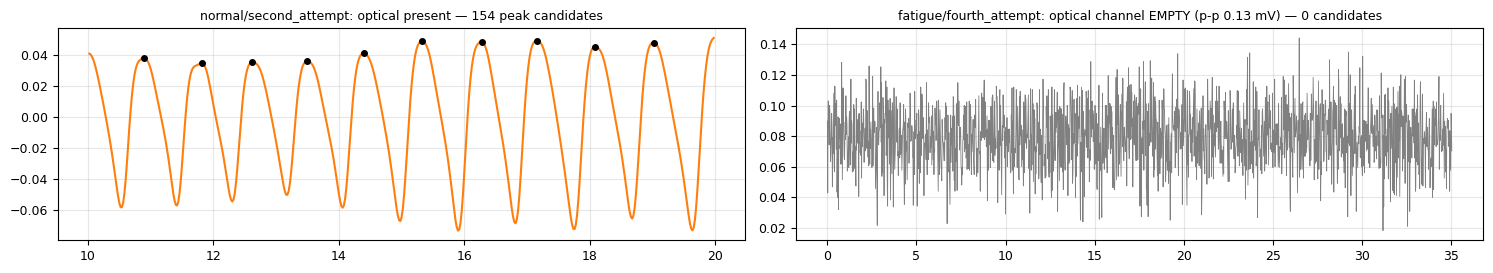

In [15]:
def optical_peaks(opt_v):
    present = np.ptp(opt_v) * 1000 > 5
    if not present:
        return present, np.array([]), None
    x = -butter(opt_v - np.median(opt_v), [0.5, 4], 'bandpass', FS_PPG)
    pk, _ = signal.find_peaks(x, distance=int(0.33*FS_PPG), prominence=0.3*np.std(x))
    return present, pk / FS_PPG, x

def match_candidates(t_r, t_p, win=(0.10, 0.80)):
    pairs, used = [], set()
    for tr in t_r:
        c = [i for i in np.where((t_p - tr >= win[0]) & (t_p - tr <= win[1]))[0] if i not in used]
        if c:
            used.add(c[0]); pairs.append(dict(ecg_peak_s=round(tr, 3), ppg_peak_s=round(t_p[c[0]], 3),
                                              delay_s=round(t_p[c[0]] - tr, 3)))
    return pd.DataFrame(pairs, columns=['ecg_peak_s', 'ppg_peak_s', 'delay_s'])

fig, ax = plt.subplots(1, 2, figsize=(15, 2.8))
for a, rid in zip(ax, ['normal/second_attempt', EX]):
    opt = recs[rid]['ch']['TIA1-3'].v.values; t_o = np.arange(len(opt)) / FS_PPG
    present, t_pk, x = optical_peaks(opt)
    if present:
        w = (t_o > 10) & (t_o < 20); a.plot(t_o[w], x[w], c='C1')
        tp = t_pk[(t_pk > 10) & (t_pk < 20)]; a.plot(tp, np.interp(tp, t_o, x), 'o', c='k', ms=4)
        a.set_title(f'{rid}: optical present — {len(t_pk)} peak candidates', fontsize=9)
    else:
        a.plot(t_o, 1000*opt, c='grey', lw=.6)
        a.set_title(f'{rid}: optical channel EMPTY (p-p {1000*np.ptp(opt):.2f} mV) — 0 candidates', fontsize=9)
plt.tight_layout(); plt.show()

### Apply P1–P8 to every recording

In [16]:
for rid, r in recs.items():
    ecg_v = r['ch']['ECG'].v.values; opt_v = r['ch']['TIA1-3'].v.values
    r['t_ecg'] = np.arange(len(ecg_v)) / FS_ECG
    r['ecg_clean'] = clean_ecg(ecg_v)
    r['mask'] = artifact_mask(ecg_v, r['ecg_clean'])
    r['rpeaks'] = pan_tompkins(r['ecg_clean'], r['mask'])
    r['t_r'] = r['t_ecg'][r['rpeaks']]
    r['t_rr'], r['rr'], r['rr_ok'] = clean_rr(r['t_r'], r['mask'])
    r['unstable'] = unstable_blocks(ecg_v, r['ecg_clean'], r['rpeaks'])
    r['keep'] = stable_range(r['unstable'])
    r['opt_present'], r['t_opt'], _ = optical_peaks(opt_v)
    r['matches'] = match_candidates(r['t_r'], r['t_opt'])

pd.DataFrame({rid: dict(masked_pct=round(100*r['mask'].mean(), 1), r_peaks=len(r['t_r']),
                        rr_kept=int(r['rr_ok'].sum()), rr_rejected=int((~r['rr_ok']).sum()),
                        stable_part=f"{r['keep'][0]:.0f}–{r['keep'][1]:.0f} s",
                        trimmed_s=round(len(r['t_ecg'])/FS_ECG - (r['keep'][1] - r['keep'][0]), 1),
                        optical_present=r['opt_present'], optical_peaks=len(r['t_opt']),
                        matches=len(r['matches'])) for rid, r in recs.items()}).T

,masked_pct,r_peaks,rr_kept,rr_rejected,stable_part,trimmed_s,optical_present,optical_peaks,matches
normal/first_attempt,0.0,151,150,0,2–138 s,3.5,True,126,110
normal/second_attempt,0.0,153,152,0,2–131 s,3.9,True,154,150
normal/third_attempt,0.0,74,73,0,2–40 s,3.3,False,0,0
normal/fourth_attempt,0.0,50,47,2,2–28 s,3.1,False,0,0
normal/fifth_attempt,0.0,55,54,0,4–30 s,5.7,False,0,0
fatigue/first_attempt,0.0,48,47,0,2–26 s,3.6,False,0,0
fatigue/second_attempt,6.1,54,52,1,7–31 s,8.9,False,0,0
fatigue/third_attempt,0.0,65,61,3,3–36 s,4.7,False,0,0
fatigue/fourth_attempt,5.7,57,54,2,3–34 s,4.1,False,0,0
fatigue/fifth_attempt,0.0,49,48,0,2–30 s,3.1,False,0,0


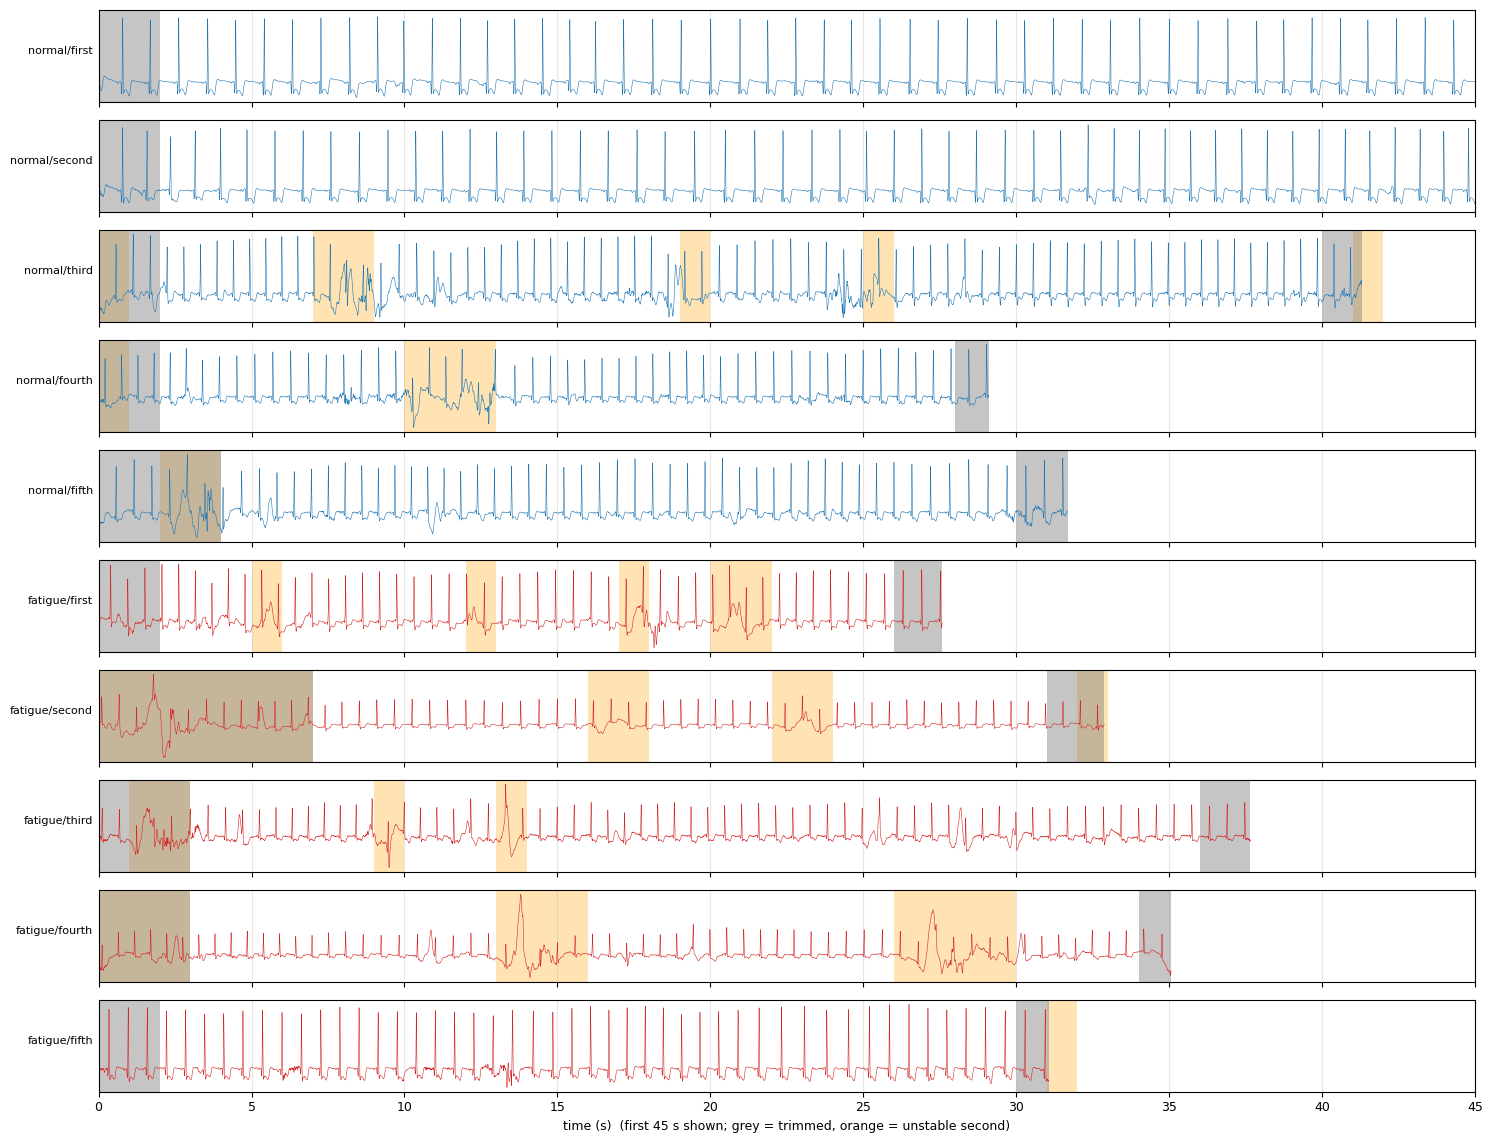

In [17]:
fig, ax = plt.subplots(len(recs), 1, figsize=(15, 1.15*len(recs)), sharex=True)
for a, (rid, r) in zip(ax, recs.items()):
    a.plot(r['t_ecg'], r['ecg_clean'], lw=.4, c='C3' if r['label'] else 'C0')
    for i, b in enumerate(r['unstable']):
        if b: a.axvspan(i, i + 1, color='orange', alpha=.3, lw=0)
    a.axvspan(0, r['keep'][0], color='grey', alpha=.45, lw=0); a.axvspan(r['keep'][1], r['t_ecg'][-1], color='grey', alpha=.45, lw=0)
    a.set_yticks([]); a.set_ylabel(rid.replace('_attempt', ''), rotation=0, ha='right', fontsize=8)
ax[0].set_xlim(0, 45); ax[-1].set_xlabel('time (s)  (first 45 s shown; grey = trimmed, orange = unstable second)')
plt.tight_layout(); plt.show()

## 4. Per-recording results (manual §9.1 Steps 29–31, Figure 21, Appendix A.4)
Each recording gets the manual's console summary, a Figure 21-style R-peak plot, and `metrics.json` + `candidate_matches.csv` under `outputs/<folder>/<file>/` (the manual's Step 27 layout).

In [18]:
def hrv(rr_s):
    ms = 1000 * rr_s; d = np.diff(ms)
    return dict(hr_mean=60000/ms.mean(), sdnn=ms.std(ddof=1), rmssd=np.sqrt(np.mean(d**2)),
                pnn50=100*np.mean(np.abs(d) > 50))

summary = []
for rid, r in recs.items():
    rr = r['rr'][r['rr_ok']]; h = hrv(rr)
    m = dict(recording=rid, condition=r['cond'], recording_s=round(len(r['t_ecg'])/FS_ECG, 2),
             ecg_fs_hz=FS_ECG, optical_fs_hz=FS_PPG, ecg_samples=len(r['t_ecg']),
             optical_samples=len(r['ch']['TIA1-3']), ecg_beat_candidates=len(r['t_r']),
             optical_peak_candidates=len(r['t_opt']), ecg_ppg_candidate_matches=len(r['matches']),
             optical_channel_present=bool(r['opt_present']), heart_rate_bpm=round(h['hr_mean'], 2),
             sdnn_ms=round(h['sdnn'], 1), rmssd_ms=round(h['rmssd'], 1), pnn50_pct=round(h['pnn50'], 1),
             masked_pct=round(100*r['mask'].mean(), 1))
    d = OUT / rid; d.mkdir(parents=True, exist_ok=True)
    (d / 'metrics.json').write_text(json.dumps(m, indent=2))
    r['matches'].to_csv(d / 'candidate_matches.csv', index=False)
    summary.append(m)
    print(f"TRACK 1 - REAL AFE4950 ANALYSIS  [{rid}]\n"
          f"  ECG beat candidates:      {m['ecg_beat_candidates']}\n"
          f"  Optical peak candidates:  {m['optical_peak_candidates']}{'' if r['opt_present'] else '  (optical channel empty)'}\n"
          f"  ECG / optical matches:    {m['ecg_ppg_candidate_matches']}\n"
          f"  Estimated heart rate:     {m['heart_rate_bpm']} BPM\n"
          f"  Record duration:          {m['recording_s']} s   (ECG {FS_ECG} Hz, optical {FS_PPG} Hz)\n"
          f"  Saved to: outputs/{rid}/")
summary = pd.DataFrame(summary).set_index('recording')

TRACK 1 - REAL AFE4950 ANALYSIS  [normal/first_attempt]
  ECG beat candidates:      151
  Optical peak candidates:  126
  ECG / optical matches:    110
  Estimated heart rate:     65.1 BPM
  Record duration:          139.54 s   (ECG 500 Hz, optical 50 Hz)
  Saved to: outputs/normal/first_attempt/
TRACK 1 - REAL AFE4950 ANALYSIS  [normal/second_attempt]
  ECG beat candidates:      153
  Optical peak candidates:  154
  ECG / optical matches:    150
  Estimated heart rate:     69.27 BPM
  Record duration:          132.94 s   (ECG 500 Hz, optical 50 Hz)
  Saved to: outputs/normal/second_attempt/
TRACK 1 - REAL AFE4950 ANALYSIS  [normal/third_attempt]
  ECG beat candidates:      74
  Optical peak candidates:  0  (optical channel empty)
  ECG / optical matches:    0
  Estimated heart rate:     108.53 BPM
  Record duration:          41.3 s   (ECG 500 Hz, optical 50 Hz)
  Saved to: outputs/normal/third_attempt/
TRACK 1 - REAL AFE4950 ANALYSIS  [normal/fourth_attempt]
  ECG beat candidates:    

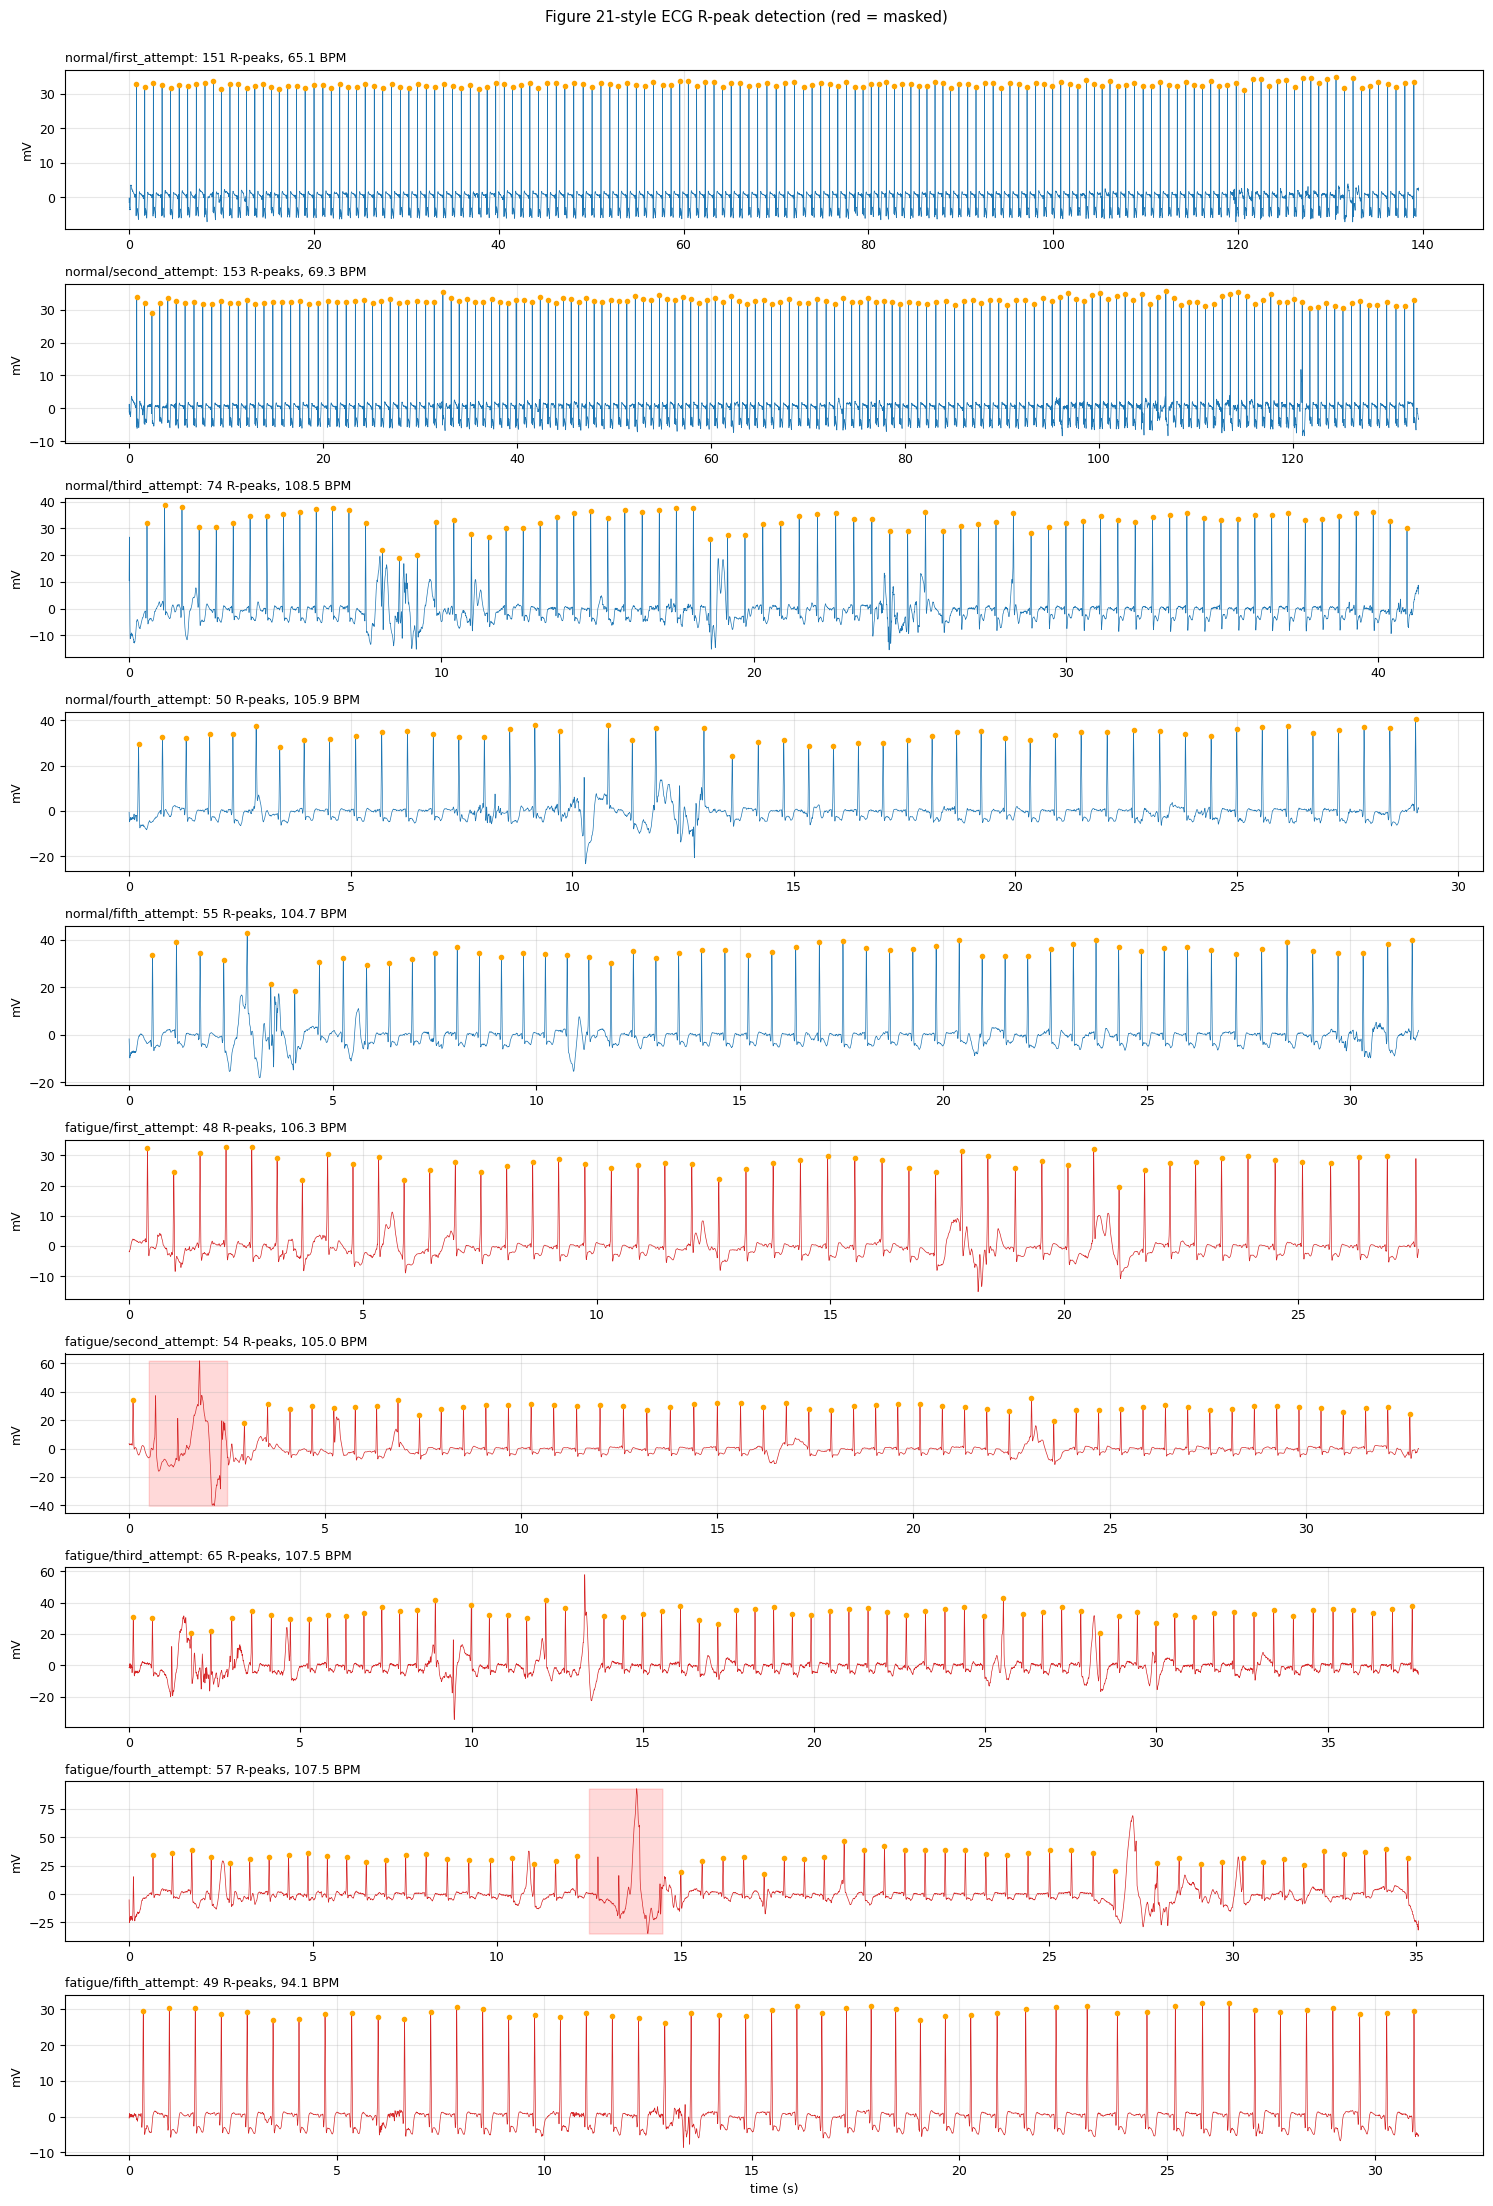

In [19]:
fig, ax = plt.subplots(len(recs), 1, figsize=(15, 2.2*len(recs)))
for a, (rid, r) in zip(ax, recs.items()):
    a.plot(r['t_ecg'], r['ecg_clean'], c='C3' if r['label'] else 'C0', lw=.5)
    a.plot(r['t_r'], r['ecg_clean'][r['rpeaks']], 'o', c='orange', ms=3)
    a.fill_between(r['t_ecg'], r['ecg_clean'].min(), r['ecg_clean'].max(), where=r['mask'], color='red', alpha=.15)
    a.set_title(f"{rid}: {len(r['t_r'])} R-peaks, {summary.loc[rid, 'heart_rate_bpm']:.1f} BPM", fontsize=9, loc='left')
    a.set_ylabel('mV')
ax[-1].set_xlabel('time (s)'); fig.suptitle('Figure 21-style ECG R-peak detection (red = masked)', y=1.0)
plt.tight_layout(); plt.show()

In [20]:
summary[['condition', 'recording_s', 'ecg_beat_candidates', 'optical_peak_candidates', 'ecg_ppg_candidate_matches',
         'heart_rate_bpm', 'sdnn_ms', 'rmssd_ms', 'pnn50_pct', 'masked_pct']]

,condition,recording_s,ecg_beat_candidates,optical_peak_candidates,ecg_ppg_candidate_matches,heart_rate_bpm,sdnn_ms,rmssd_ms,pnn50_pct,masked_pct
recording,,,,,,,,,,
normal/first_attempt,normal,139.54,151,126,110,65.10,38.9,38.7,21.5,0.0
normal/second_attempt,normal,132.94,153,154,150,69.27,52.5,33.4,11.9,0.0
normal/third_attempt,normal,41.30,74,0,0,108.53,15.7,6.6,0.0,0.0
normal/fourth_attempt,normal,29.10,50,0,0,105.89,21.8,19.1,2.2,0.0
normal/fifth_attempt,normal,31.68,55,0,0,104.69,24.0,8.1,0.0,0.0
fatigue/first_attempt,fatigue,27.58,48,0,0,106.34,17.9,7.4,0.0,0.0
fatigue/second_attempt,fatigue,32.88,54,0,0,104.99,13.7,6.0,0.0,6.1
fatigue/third_attempt,fatigue,37.66,65,0,0,107.50,18.7,8.9,0.0,0.0
fatigue/fourth_attempt,fatigue,35.06,57,0,0,107.54,23.2,8.3,0.0,5.7


**Interpretation (manual §9.2):** R-peaks are beat *candidates* found by the algorithm. Optical candidates and ECG/optical matches are internal matching events, **not** validated pulse transit time or blood pressure. Only recordings with a working optical channel can produce optical candidates.

## 5. Normal vs. fatigue: recording-level comparison

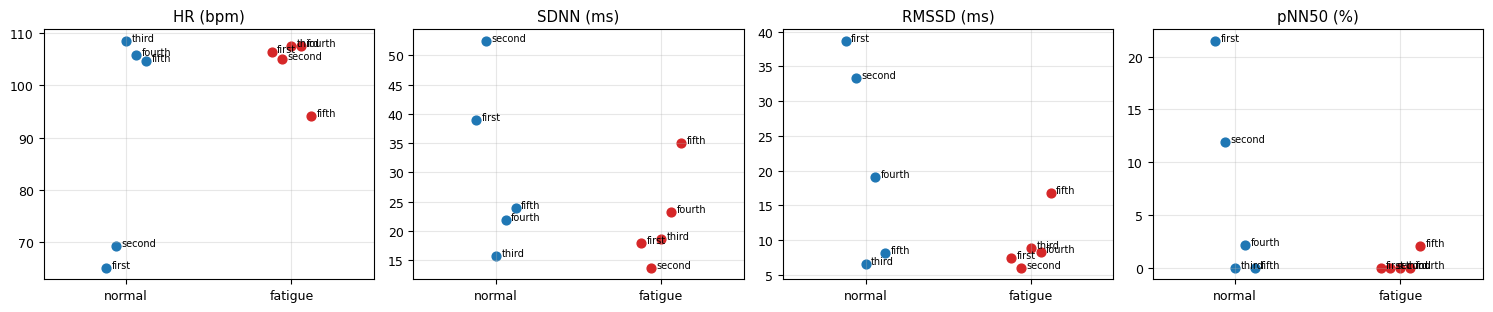

condition            fatigue  normal
recording_s    mean     32.8    74.9
               min      27.6    29.1
               max      37.7   139.5
heart_rate_bpm mean    104.1    90.7
               min      94.1    65.1
               max     107.5   108.5
sdnn_ms        mean     21.7    30.6
               min      13.7    15.7
               max      35.0    52.5
rmssd_ms       mean      9.5    21.2
               min       6.0     6.6
               max      16.8    38.7
pnn50_pct      mean      0.4     7.1
               min       0.0     0.0
               max       2.1    21.5

In [21]:
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for a, k, lab in zip(ax, ['heart_rate_bpm', 'sdnn_ms', 'rmssd_ms', 'pnn50_pct'], ['HR (bpm)', 'SDNN (ms)', 'RMSSD (ms)', 'pNN50 (%)']):
    for i, cond in enumerate(CONDITIONS):
        v = summary[summary.condition == cond]
        a.scatter(np.full(len(v), i) + np.linspace(-.12, .12, len(v)), v[k], s=40, c='C3' if i else 'C0')
        for x_, (n, y_) in zip(np.full(len(v), i) + np.linspace(-.12, .12, len(v)), v[k].items()):
            a.annotate(n.split('/')[1].split('_')[0], (x_, y_), fontsize=7, xytext=(4, 0), textcoords='offset points')
    a.set_xticks([0, 1], list(CONDITIONS)); a.set_title(lab); a.set_xlim(-.5, 1.5)
plt.tight_layout(); plt.show()
summary.groupby('condition')[['recording_s', 'heart_rate_bpm', 'sdnn_ms', 'rmssd_ms', 'pnn50_pct']].agg(['mean', 'min', 'max']).round(1).T

**What the comparison shows**
- On averages, fatigue looks as expected: **higher HR** (104 vs 91 bpm) and **lower HRV** (RMSSD 9.5 vs 21 ms, pNN50 0.4 vs 7 %).
- **But the averages are driven by `normal/first` and `normal/second` alone.** These two (HR 65–69 bpm, RMSSD 33–39 ms) come from the other recording setup.
- **`normal/third–fifth` look just like the fatigue recordings:** HR 105–109 bpm, RMSSD 7–19 ms, pNN50 0–2 %. A resting HR above 100 bpm is unusual. These "normal" sessions were probably recorded right after activity, or the subject wasn't actually rested.
- So there are two plausible explanations for any difference: **fatigue**, or **session/setup**. Only a model test on held-out recordings can tell which (§7).


## 6. Windowing and features (P9)
Recordings are only about 30 s long, which is too short for one value per recording to train a model. The **stable part** of each recording (after P7b trimming) is therefore cut into **20 s windows every 5 s**, giving one feature row per window.

**Features: ECG time-domain HRV only.**
- `hr_mean`: mean heart rate (bpm)
- `sdnn`: standard deviation of RR intervals (ms), overall variability
- `rmssd`: root mean square of successive RR differences (ms), short-term vagal activity
- `pnn50`: % of successive RR differences > 50 ms

**Left out on purpose:**
- **Frequency-domain HRV (LF, HF, LF/HF):** needs ≥ 2 min of data (Task Force of ESC/NASPE, 1996). RMSSD is the measure considered valid down to about 10 s.
- **Breathing rate / optical features:** the optical channel is empty in 8 of 10 recordings.
- **Signal amplitude and noise:** these reflect electrode placement and mains pickup, not physiology.

**Quality gate:** a window needs ≥ 15 clean RR intervals and ≤ 20 % masked samples.

In [22]:
WIN_S, HOP_S, MIN_RR, MAX_MASKED = 20, 5, 15, 0.20
FEATURES = ['hr_mean', 'sdnn', 'rmssd', 'pnn50']

def window_starts(r, trim=True):
    # window start times inside the stable part (P7b) — or the whole recording if trim=False
    a, b = r['keep'] if trim else (0.0, len(r['t_ecg']) / FS_ECG)
    return np.arange(a, b - WIN_S + 1e-9, HOP_S)

def window_table(rid, r, trim=True):
    rows = []
    for s in window_starts(r, trim):
        sel = r['rr_ok'] & (r['t_rr'] >= s) & (r['t_rr'] < s + WIN_S)
        masked = r['mask'][int(s*FS_ECG):int((s+WIN_S)*FS_ECG)].mean()
        row = dict(recording=rid, condition=r['cond'], label=r['label'], start_s=s, n_rr=int(sel.sum()), masked=masked)
        if sel.sum() >= MIN_RR and masked <= MAX_MASKED:
            row.update(hrv(r['rr'][sel])); row['ok'] = True
        else:
            row['ok'] = False
        rows.append(row)
    return rows

W = pd.DataFrame([row for rid, r in recs.items() for row in window_table(rid, r)])
print(f"{len(W)} windows, {W.ok.sum()} pass the quality gate")
W = W[W.ok].reset_index(drop=True)
W.groupby(['condition', 'recording']).agg(windows=('label', 'size'), hr=('hr_mean', 'mean'),
                                          rmssd=('rmssd', 'mean')).round(1)

64 windows, 64 pass the quality gate


windows     hr  rmssd
condition recording                                    
fatigue   fatigue/fifth_attempt         2   94.8   17.9
          fatigue/first_attempt         1  106.9    7.1
          fatigue/fourth_attempt        3  106.9    7.6
          fatigue/second_attempt        1  104.3    5.7
          fatigue/third_attempt         3  108.5    6.3
normal    normal/fifth_attempt          2  106.2    7.0
          normal/first_attempt         24   65.1   38.1
          normal/fourth_attempt         2  105.8   23.0
          normal/second_attempt        22   69.4   33.7
          normal/third_attempt          4  107.7    6.8

## 7. Simple classifier: logistic regression

**Model:** standardise the features, then logistic regression (`class_weight='balanced'`). It's a linear model with 4 coefficients, easy to interpret and small enough to run on the SK-AM62B.

**Fair evaluation, leave-one-recording-out (LORO):** windows from the same recording overlap and are nearly identical, so a random train/test split would leak information and inflate accuracy. Instead, each recording is held out in turn: train on the other 9, predict all windows of the held-out one. The recording's prediction is the **mean probability of its windows**.

**Equal weight per recording:** the two long normal recordings produce about 5× more windows than the others. Each window gets weight 1 / (number of windows in its recording), so every recording counts equally.

**Two experiments:**
- **A. All 10 recordings.**
- **B. Matched set:** `normal/third–fifth` vs. all `fatigue`. These are the short recordings from the same apparent session and setup (optical off, similar length). This tests whether fatigue is still detectable once the different setup of `normal/first` and `normal/second` is taken out.

In [23]:
def make_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000))

def loro(df, features=FEATURES):
    X, y, g = df[features].values, df.label.values, df.recording.values
    w = 1 / df.groupby('recording').recording.transform('size').values
    prob = np.zeros(len(df))
    for tr, te in LeaveOneGroupOut().split(X, y, g):
        m = make_model().fit(X[tr], y[tr], logisticregression__sample_weight=w[tr] / w[tr].mean())
        prob[te] = m.predict_proba(X[te])[:, 1]
    per_rec = df.assign(prob=prob).groupby('recording').agg(label=('label', 'first'), p_fatigue=('prob', 'mean'),
                                                            windows=('prob', 'size'))
    per_rec['predicted'] = np.where(per_rec.p_fatigue >= .5, 'fatigue', 'normal')
    per_rec['correct'] = (per_rec.p_fatigue >= .5).astype(int) == per_rec.label
    res = dict(window_bal_acc=balanced_accuracy_score(y, prob >= .5),
               recording_acc=per_rec.correct.mean(), recordings=len(per_rec))
    return res, per_rec, prob

experiments = {'A: all 10 recordings': W,
               'B: matched (normal 3-5 vs fatigue)': W[~W.recording.isin(['normal/first_attempt', 'normal/second_attempt'])]}
feature_sets = {'HR only': ['hr_mean'], 'HRV only (sdnn, rmssd, pnn50)': ['sdnn', 'rmssd', 'pnn50'], 'all 4 features': FEATURES}
rows, per_rec_tables = [], {}
for en, df in experiments.items():
    for fn, feats in feature_sets.items():
        res, per_rec, _ = loro(df, feats)
        rows.append(dict(experiment=en, features=fn, **{k: round(v, 3) if isinstance(v, float) else v for k, v in res.items()}))
        if fn == 'all 4 features':
            per_rec_tables[en] = per_rec
pd.DataFrame(rows).set_index(['experiment', 'features'])

window_bal_acc  \
experiment                         features                                        
A: all 10 recordings               HR only                                 0.926   
                                   HRV only (sdnn, rmssd, pnn50)           0.839   
                                   all 4 features                          0.802   
B: matched (normal 3-5 vs fatigue) HR only                                 0.400   
                                   HRV only (sdnn, rmssd, pnn50)           0.400   
                                   all 4 features                          0.362   

                                                                  recording_acc  \
experiment                         features                                       
A: all 10 recordings               HR only                                0.700   
                                   HRV only (sdnn, rmssd, pnn50)          0.600   
                                   all 4 features                         0.600   
B: matched (normal 3-5 vs fatigue) HR only                                0.375   
                                   HRV only (sdnn, rmssd, pnn50)          0.500   
                                   all 4 features                         0.500   

                                                                  recordings  
experiment                         features                                   
A: all 10 recordings               HR only                                10  
                                   HRV only (sdnn, rmssd, pnn50)          10  
                                   all 4 features                         10  
B: matched (normal 3-5 vs fatigue) HR only                                 8  
                                   HRV only (sdnn, rmssd, pnn50)           8  
                                   all 4 features                          8

A: all 10 recordings


,label,p_fatigue,windows,predicted,correct
recording,,,,,
fatigue/fifth_attempt,1,0.33,2,normal,False
fatigue/first_attempt,1,0.91,1,fatigue,True
fatigue/fourth_attempt,1,0.94,3,fatigue,True
fatigue/second_attempt,1,0.91,1,fatigue,True
fatigue/third_attempt,1,0.93,3,fatigue,True
normal/fifth_attempt,0,0.96,2,fatigue,False
normal/first_attempt,0,0.12,24,normal,True
normal/fourth_attempt,0,0.86,2,fatigue,False
normal/second_attempt,0,0.41,22,normal,True


recording-level confusion matrix [rows = true normal/fatigue, cols = predicted normal/fatigue]:
 [[2 3]
 [1 4]] 

B: matched (normal 3-5 vs fatigue)


,label,p_fatigue,windows,predicted,correct
recording,,,,,
fatigue/fifth_attempt,1,0.08,2,normal,False
fatigue/first_attempt,1,0.55,1,fatigue,True
fatigue/fourth_attempt,1,0.57,3,fatigue,True
fatigue/second_attempt,1,0.71,1,fatigue,True
fatigue/third_attempt,1,0.51,3,fatigue,True
normal/fifth_attempt,0,0.75,2,fatigue,False
normal/fourth_attempt,0,0.91,2,fatigue,False
normal/third_attempt,0,0.56,4,fatigue,False


recording-level confusion matrix [rows = true normal/fatigue, cols = predicted normal/fatigue]:
 [[0 3]
 [1 4]] 



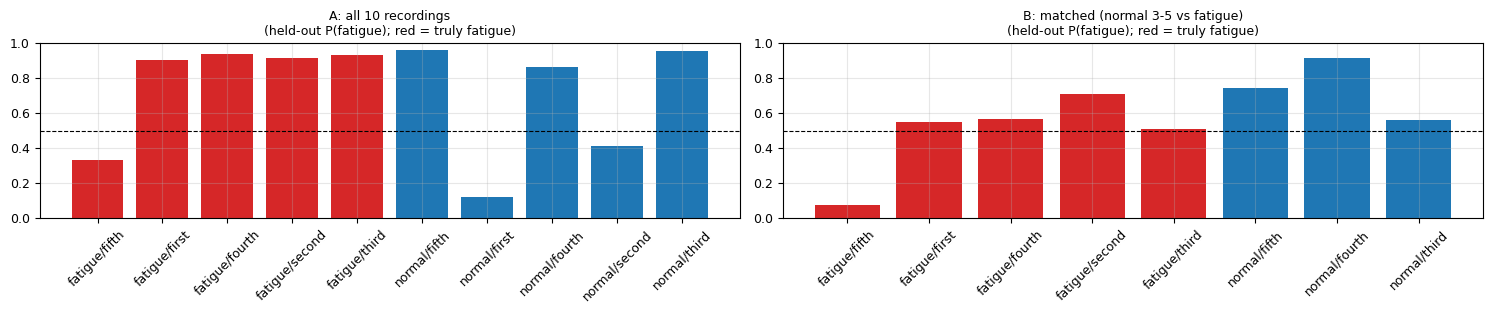

In [24]:
for en, pr in per_rec_tables.items():
    print(en); display(pr.assign(p_fatigue=pr.p_fatigue.round(2)))
    cm = confusion_matrix(pr.label, (pr.p_fatigue >= .5).astype(int), labels=[0, 1])
    print('recording-level confusion matrix [rows = true normal/fatigue, cols = predicted normal/fatigue]:\n', cm, '\n')

fig, ax = plt.subplots(1, 2, figsize=(15, 3.2))
for a, (en, pr) in zip(ax, per_rec_tables.items()):
    a.bar(pr.index.str.replace('_attempt', ''), pr.p_fatigue, color=['C3' if l else 'C0' for l in pr.label])
    a.axhline(.5, ls='--', c='k', lw=.8); a.set_ylim(0, 1); a.set_title(f'{en}\n(held-out P(fatigue); red = truly fatigue)', fontsize=9)
    a.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

In [25]:
# Final model: all recordings, all 4 features (recording-weighted) — coefficients and export
w = 1 / W.groupby('recording').recording.transform('size').values
final = make_model().fit(W[FEATURES].values, W.label.values, logisticregression__sample_weight=w / w.mean())
sc, lr = final.named_steps['standardscaler'], final.named_steps['logisticregression']
coef = pd.Series(lr.coef_[0], FEATURES).sort_values(key=abs, ascending=False)
print('standardised coefficients (+ = pushes towards fatigue):'); print(coef.round(3).to_string())

model = dict(type='standardized_logistic_regression', features=FEATURES, mean=sc.mean_.tolist(), scale=sc.scale_.tolist(),
             coef=lr.coef_[0].tolist(), intercept=float(lr.intercept_[0]), threshold=0.5,
             window_s=WIN_S, hop_s=HOP_S, trained_on=sorted(W.recording.unique().tolist()),
             loro_recording_accuracy={r['experiment'] + ' | ' + r['features']: r['recording_acc'] for r in rows})
(OUT / 'fatigue_model.json').write_text(json.dumps(model, indent=2))
print('\nsaved outputs/fatigue_model.json')

standardised coefficients (+ = pushes towards fatigue):
rmssd     -1.858
pnn50     -0.664
sdnn       0.553
hr_mean    0.080

saved outputs/fatigue_model.json


### Classify a new recording
Apply the same preprocessing (P1–P9) and the saved model to any new TI export:

In [26]:
def classify_recording(path, model_path=OUT / 'fatigue_model.json'):
    mdl = json.loads(Path(model_path).read_text())
    ch = load_recording(path); ecg_v = ch['ECG'].v.values
    r = dict(cond='?', label=-1, t_ecg=np.arange(len(ecg_v)) / FS_ECG)
    r['ecg_clean'] = clean_ecg(ecg_v); r['mask'] = artifact_mask(ecg_v, r['ecg_clean'])
    r['rpeaks'] = pan_tompkins(r['ecg_clean'], r['mask'])
    r['t_rr'], r['rr'], r['rr_ok'] = clean_rr(r['t_ecg'][r['rpeaks']], r['mask'])
    r['keep'] = stable_range(unstable_blocks(ecg_v, r['ecg_clean'], r['rpeaks']))   # P7b
    win = pd.DataFrame(window_table(str(path), r)); win = win[win.ok]
    if win.empty:
        return 'insufficient clean signal (need >= 20 s with >= 15 clean beats)', win
    z = (win[mdl['features']].values - mdl['mean']) / np.array(mdl['scale'])
    win['p_fatigue'] = 1 / (1 + np.exp(-(z @ np.array(mdl['coef']) + mdl['intercept'])))
    p = win.p_fatigue.mean()
    return f"{'FATIGUE' if p >= mdl['threshold'] else 'NORMAL'} (mean P(fatigue) = {p:.2f} over {len(win)} windows)", win

verdict, detail = classify_recording(ROOT / 'fatigue' / 'second_attempt.csv')
print('fatigue/second_attempt.csv ->', verdict, '   (note: this recording was in the training set)')
detail[['start_s', 'hr_mean', 'rmssd', 'p_fatigue']].round(2)

fatigue/second_attempt.csv -> FATIGUE (mean P(fatigue) = 0.93 over 1 windows)    (note: this recording was in the training set)


,start_s,hr_mean,rmssd,p_fatigue
0,7.0,104.29,5.66,0.93


## 8. Model comparison with 5-fold cross-validation

This section tries **five different classifiers** on the preprocessed windows, with **5-fold cross-validation** under two splitting schemes:

| Scheme | How the 5 folds are made | What it measures |
|---|---|---|
| **Window-level** `StratifiedKFold(5)` | 20 s windows shuffled into 5 folds; windows of the same recording go to both train and test | How well the model **recognises recordings it has already seen**. Windows overlap by 15 s, so test windows are near-copies of training windows (**data leakage**) |
| **Recording-level** `StratifiedGroupKFold(5)` | Whole recordings go to one fold (2 recordings per fold) | How well the model classifies a **new, unseen recording**, which is the real use case |

**Feature sets**
- `HRV-4`: hr_mean, sdnn, rmssd, pnn50 (as in §7)
- `ECG-9`: HRV-4 plus hr_min, hr_max, rr_cv (SDNN / mean RR), sd1_sd2 (Poincaré short/long-term variability), and r_amp_cv (beat-to-beat R-amplitude variation, which is modulated by breathing)

In [27]:
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

def extended_window_table(rid, r, trim=True):
    rows = []
    t_peaks = r['t_ecg'][r['rpeaks']]; amp = np.abs(r['ecg_clean'][r['rpeaks']])
    for s in window_starts(r, trim):
        sel = r['rr_ok'] & (r['t_rr'] >= s) & (r['t_rr'] < s + WIN_S)
        masked = r['mask'][int(s*FS_ECG):int((s+WIN_S)*FS_ECG)].mean()
        if sel.sum() < MIN_RR or masked > MAX_MASKED:
            continue
        rr = r['rr'][sel]; ms = 1000*rr; d = np.diff(ms)
        sd1 = np.sqrt(.5)*np.std(d, ddof=1); sdnn = ms.std(ddof=1)
        a = amp[(t_peaks >= s) & (t_peaks < s + WIN_S)]
        rows.append(dict(recording=rid, condition=r['cond'], label=r['label'], start_s=s, **hrv(rr),
                         hr_min=60/rr.max(), hr_max=60/rr.min(), rr_cv=sdnn/ms.mean(),
                         sd1_sd2=sd1/np.sqrt(max(2*sdnn**2 - sd1**2, 1e-9)), r_amp_cv=a.std()/a.mean()))
    return rows

WX = pd.DataFrame([row for rid, r in recs.items() for row in extended_window_table(rid, r)])
FEATURE_SETS = {'HRV-4': FEATURES, 'ECG-9': FEATURES + ['hr_min', 'hr_max', 'rr_cv', 'sd1_sd2', 'r_amp_cv']}
MODELS = {
    'Logistic regression': lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000)),
    'SVM (RBF)':           lambda: make_pipeline(StandardScaler(), SVC(C=3, gamma='scale', class_weight='balanced', probability=True, random_state=0)),
    'Random forest':       lambda: RandomForestClassifier(300, min_samples_leaf=2, class_weight='balanced', random_state=0),
    'Gradient boosting':   lambda: GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=.1, random_state=0),
    'k-NN (k=5)':          lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
}
SCHEMES = {
    'window-level 5-fold (leaky)':     lambda: StratifiedKFold(5, shuffle=True, random_state=0),
    'recording-level 5-fold (honest)': lambda: StratifiedGroupKFold(5, shuffle=True, random_state=0),
}

def cross_validate(df, feats, make, scheme):
    X, y, g = df[feats].values, df.label.values, df.recording.values
    prob = np.zeros(len(df)); folds = []
    for tr, te in SCHEMES[scheme]().split(X, y, g):
        m = make().fit(X[tr], y[tr]); prob[te] = m.predict_proba(X[te])[:, 1]
        folds.append(np.mean((prob[te] >= .5) == y[te]))
    rec = df.assign(p=prob).groupby('recording').agg(label=('label', 'first'), p=('p', 'mean'))
    return dict(window_acc=np.mean((prob >= .5) == y), window_bal_acc=balanced_accuracy_score(y, prob >= .5),
                fold_acc=' / '.join(f'{a:.2f}' for a in folds),
                recording_acc=np.mean((rec.p >= .5) == rec.label)), prob

rows, probs = [], {}
for scheme in SCHEMES:
    for fs_name, feats in FEATURE_SETS.items():
        for mname, make in MODELS.items():
            res, p = cross_validate(WX, feats, make, scheme)
            probs[(scheme, fs_name, mname)] = p
            rows.append(dict(scheme=scheme, features=fs_name, model=mname, **res))
cv = pd.DataFrame(rows)
print(f'{len(WX)} windows (stable part only, P7b) from {WX.recording.nunique()} recordings '
      f'({(WX.label == 0).sum()} normal, {(WX.label == 1).sum()} fatigue windows)')
cv.set_index(['scheme', 'features', 'model']).round(3)

64 windows (stable part only, P7b) from 10 recordings (54 normal, 10 fatigue windows)


window_acc  \
scheme                          features model                             
window-level 5-fold (leaky)     HRV-4    Logistic regression       0.859   
                                         SVM (RBF)                 0.844   
                                         Random forest             0.844   
                                         Gradient boosting         0.812   
                                         k-NN (k=5)                0.766   
                                ECG-9    Logistic regression       0.844   
                                         SVM (RBF)                 0.828   
                                         Random forest             0.828   
                                         Gradient boosting         0.891   
                                         k-NN (k=5)                0.828   
recording-level 5-fold (honest) HRV-4    Logistic regression       0.859   
                                         SVM (RBF)                 0.734   
                                         Random forest             0.734   
                                         Gradient boosting         0.734   
                                         k-NN (k=5)                0.734   
                                ECG-9    Logistic regression       0.812   
                                         SVM (RBF)                 0.734   
                                         Random forest             0.734   
                                         Gradient boosting         0.766   
                                         k-NN (k=5)                0.734   

                                                              window_bal_acc  \
scheme                          features model                                 
window-level 5-fold (leaky)     HRV-4    Logistic regression           0.876   
                                         SVM (RBF)                     0.785   
                                         Random forest                 0.826   
                                         Gradient boosting             0.604   
                                         k-NN (k=5)                    0.576   
                                ECG-9    Logistic regression           0.826   
                                         SVM (RBF)                     0.735   
                                         Random forest                 0.776   
                                         Gradient boosting             0.772   
                                         k-NN (k=5)                    0.776   
recording-level 5-fold (honest) HRV-4    Logistic regression           0.876   
                                         SVM (RBF)                     0.476   
                                         Random forest                 0.476   
                                         Gradient boosting             0.476   
                                         k-NN (k=5)                    0.476   
                                ECG-9    Logistic regression           0.726   
                                         SVM (RBF)                     0.476   
                                         Random forest                 0.476   
                                         Gradient boosting             0.576   
                                         k-NN (k=5)                    0.476   

                                                                                      fold_acc  \
scheme                          features model                                                   
window-level 5-fold (leaky)     HRV-4    Logistic regression  0.77 / 0.92 / 0.92 / 0.92 / 0.75   
                                         SVM (RBF)            0.77 / 1.00 / 0.85 / 0.85 / 0.75   
                                         Random forest        0.77 / 0.92 / 0.85 / 0.92 / 0.75   
                                         Gradient boosting    0.77 / 0.77 / 0.85 / 0.85 / 0.83   
                                        

### Effect of trimming the unstable start and end (P7b)
The same 5-fold experiments, run on windows from the **whole recording** vs. only the **stable part**:

In [28]:
WX_full = pd.DataFrame([row for rid, r in recs.items() for row in extended_window_table(rid, r, trim=False)])
rows_full = []
for scheme in SCHEMES:
    for fs_name, feats in FEATURE_SETS.items():
        for mname, make in MODELS.items():
            res, _ = cross_validate(WX_full, feats, make, scheme)
            rows_full.append(dict(scheme=scheme, features=fs_name, model=mname, **res))
cmp = pd.concat({'whole recording': pd.DataFrame(rows_full).set_index(['scheme', 'features', 'model']),
                 'stable part (trimmed)': cv.set_index(['scheme', 'features', 'model'])}, axis=1)
counts = pd.DataFrame({'whole recording': WX_full.groupby('recording').size(),
                       'stable part (trimmed)': WX.groupby('recording').size()}).fillna(0).astype(int)
print('windows per recording:'); display(counts.T)
cmp.xs('recording_acc', axis=1, level=1).join(cmp.xs('window_bal_acc', axis=1, level=1), lsuffix=' | recording acc',
                                                rsuffix=' | window bal. acc').round(2)

windows per recording:


recording,fatigue/fifth_attempt,fatigue/first_attempt,fatigue/fourth_attempt,fatigue/second_attempt,fatigue/third_attempt,normal/fifth_attempt,normal/first_attempt,normal/fourth_attempt,normal/second_attempt,normal/third_attempt
whole recording,3,2,4,3,4,3,24,2,23,5
stable part (trimmed),2,1,3,1,3,2,24,2,22,4


whole recording | recording acc  \
scheme                          features model                                                  
window-level 5-fold (leaky)     HRV-4    Logistic regression                              0.6   
                                         SVM (RBF)                                        0.6   
                                         Random forest                                    0.6   
                                         Gradient boosting                                0.5   
                                         k-NN (k=5)                                       0.6   
                                ECG-9    Logistic regression                              0.6   
                                         SVM (RBF)                                        0.6   
                                         Random forest                                    0.6   
                                         Gradient boosting                                0.7   
                                         k-NN (k=5)                                       0.6   
recording-level 5-fold (honest) HRV-4    Logistic regression                              0.6   
                                         SVM (RBF)                                        0.6   
                                         Random forest                                    0.5   
                                         Gradient boosting                                0.4   
                                         k-NN (k=5)                                       0.6   
                                ECG-9    Logistic regression                              0.6   
                                         SVM (RBF)                                        0.5   
                                         Random forest                                    0.5   
                                         Gradient boosting                                0.3   
                                         k-NN (k=5)                                       0.5   

                                                              stable part (trimmed) | recording acc  \
scheme                          features model                                                        
window-level 5-fold (leaky)     HRV-4    Logistic regression                                    0.6   
                                         SVM (RBF)                                              0.6   
                                         Random forest                                          0.6   
                                         Gradient boosting                                      0.4   
                                         k-NN (k=5)                                             0.3   
                                ECG-9    Logistic regression                                    0.6   
                                         SVM (RBF)                                              0.5   
                                         Random forest                                          0.6   
                                         Gradient boosting                                      0.7   
                                         k-NN (k=5)                                             0.6   
recording-level 5-fold (honest) HRV-4    Logistic regression                                    0.6   
                                         SVM (RBF)                                              0.3   
                                         Random forest                                          0.3   
                                         Gradient boosting                                      0.3   
                                         k-NN (k=5)                                             0.3   
                                ECG-9    Logistic regression                                    0.5   
                                         SVM (RBF)                       

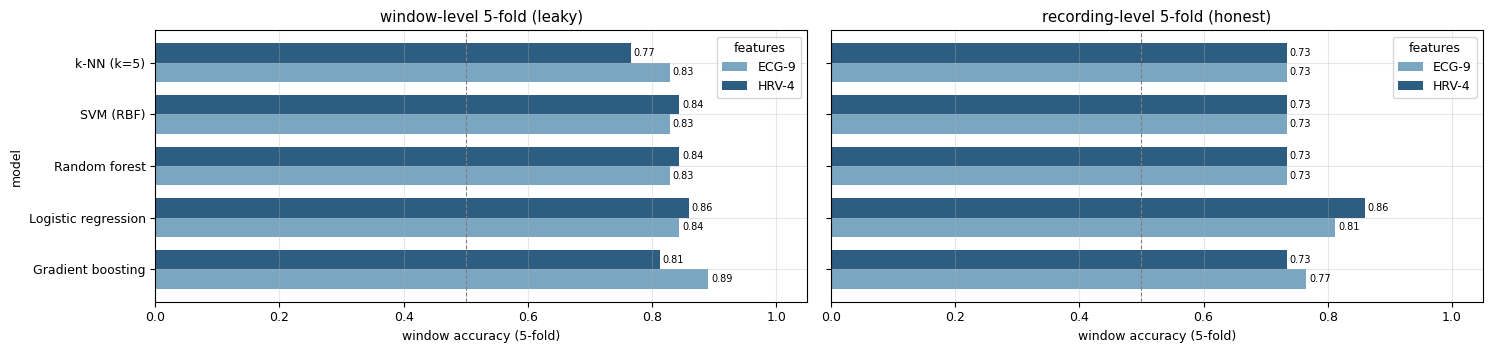

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6), sharey=True)
for a, scheme in zip(ax, SCHEMES):
    sub = cv[cv.scheme == scheme].pivot(index='model', columns='features', values='window_acc')
    sub.plot.barh(ax=a, color=['#7aa6c2', '#2e5d82'], width=.75)
    a.axvline(.5, ls='--', c='grey', lw=.8); a.set_xlim(0, 1.05); a.set_title(scheme); a.set_xlabel('window accuracy (5-fold)')
    for c in a.containers: a.bar_label(c, fmt='%.2f', fontsize=7, padding=2)
plt.tight_layout(); plt.show()

**Reading the 5-fold results (stable part only, after P7b trimming)**
- **Baseline:** after trimming, 54 of the 64 windows are normal, so a model that always answers "normal" already gets **84 % window accuracy**. Balanced accuracy and recording accuracy are the fair metrics.
- **No model reaches 100 %, under either scheme.** The best window-level (leaky) result is gradient boosting on ECG-9 at 89 % (57 / 64), only 3 windows better than always saying "normal". Even with near-duplicate windows in the training set it can't do better, because `normal/third–fifth` and the fatigue windows have nearly identical HR and HRV.
- **Recording-level (honest):** the best model is again the simplest, **logistic regression on HRV-4: 6 of 10 recordings (60 %)**, balanced window accuracy 0.88. The other four models fall back to predicting almost everything "normal" (balanced accuracy 0.48, 3 / 10 recordings). With only 10 fatigue windows left after trimming, they have too little fatigue data to learn from.
- **Fold accuracies swing between 0 and 100 %** depending on which 2 recordings are held out. That instability is typical when there are too few independent samples.
- **Trimming** (table below) removed shaky edges, but it didn't change the picture. Logistic regression stays at 6 / 10, and the flexible models lose fatigue windows and get worse.
- The cell after the table shows what window-level accuracy really measures: the models can tell **which recording** a window came from much better than chance.


In [30]:
# Where does the window-level "accuracy" come from?  Recording identity.
# Same window-level 5-fold, but the label to predict is WHICH RECORDING the window came from (10 classes).
X = WX[FEATURE_SETS['ECG-9']].values
ident = []
for mname in ['Random forest', 'k-NN (k=5)']:
    pred = np.empty(len(WX), dtype=object)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, WX.recording):
        pred[te] = MODELS[mname]().fit(X[tr], WX.recording.values[tr]).predict(X[te])
    ident.append(dict(model=mname, recording_identification_acc=np.mean(pred == WX.recording.values)))
pd.DataFrame(ident).assign(chance=1/WX.recording.nunique()).round(2)

,model,recording_identification_acc,chance
0,Random forest,0.81,0.1
1,k-NN (k=5),0.70,0.1


In [31]:
best = cv[cv.scheme.str.startswith('recording')].sort_values(['recording_acc', 'window_bal_acc'], ascending=False).iloc[0]
key = ('recording-level 5-fold (honest)', best.features, best.model)
rec = WX.assign(p=probs[key]).groupby('recording').agg(label=('label', 'first'), p_fatigue=('p', 'mean'), windows=('p', 'size'))
rec['predicted'] = np.where(rec.p_fatigue >= .5, 'fatigue', 'normal'); rec['correct'] = (rec.p_fatigue >= .5) == rec.label
print(f'Best honest model: {best.model} on {best.features} — recording accuracy {best.recording_acc:.0%}')
print('confusion matrix (rows true normal/fatigue, cols predicted):\n',
      confusion_matrix(rec.label, (rec.p_fatigue >= .5).astype(int), labels=[0, 1]))
rec.round(2)

Best honest model: Logistic regression on HRV-4 — recording accuracy 60%
confusion matrix (rows true normal/fatigue, cols predicted):
 [[2 3]
 [1 4]]


,label,p_fatigue,windows,predicted,correct
recording,,,,,
fatigue/fifth_attempt,1,0.40,2,normal,False
fatigue/first_attempt,1,0.89,1,fatigue,True
fatigue/fourth_attempt,1,0.82,3,fatigue,True
fatigue/second_attempt,1,0.79,1,fatigue,True
fatigue/third_attempt,1,0.90,3,fatigue,True
normal/fifth_attempt,0,0.93,2,fatigue,False
normal/first_attempt,0,0.03,24,normal,True
normal/fourth_attempt,0,0.77,2,fatigue,False
normal/second_attempt,0,0.17,22,normal,True


## 9. Conclusions

### Preprocessing (manual §7–9): works
- All 10 exports load and verify correctly (Steps 23–24, `index_col=False`).
- **P1–P4 filtering** removes baseline wander and mains noise (60 Hz power 9.5× → 0.003× of ECG power on the worst file), and smooths muscle noise without blunting R-peaks.
- **P7b** trims the unstable start and end (3–9 s per recording, e.g. the first 7 s of `fatigue/second`), so features come only from the stable part.
- **P5–P7** stop motion spikes from becoming false beats. Without the 2× mask and amplitude validation, motion artifacts inflated `fatigue/fourth`'s RMSSD from about 8 to 37 ms.
- Per-recording `metrics.json` and `candidate_matches.csv` are in `outputs/`. Optical candidates and matches exist only for the 2 recordings with a working optical sensor.

### Classifier: does not detect fatigue on this data
| Test (held-out recordings) | Recording accuracy | Meaning |
|---|---|---|
| A: all 10 recordings (leave-one-out) | 6 / 10 (60 %) | barely above chance; correct mainly on `normal/first` and `normal/second`, which differ by setup |
| B: matched, normal 3–5 vs fatigue 1–5 | 4 / 8 (50 %) | chance level once the setup difference is removed |
| §8: 5 models × 2 feature sets, recording-level 5-fold | best 6 / 10 (60 %), logistic regression on HRV-4 | other models 3 / 10, mostly predicting "normal" |
| §8: same, window-level 5-fold (leaky) | best 89 % of windows (57 / 64) | always answering "normal" already gets 84 % (54 / 64) |
| §8: whole recording vs. trimmed stable part | no improvement from trimming | the shaky edges were not the cause |

Window-level accuracy looks better in A only because the 46 windows from the two long normal recordings are easy. Those reflect setup and resting HR, not fatigue.

**Why not 100 %:** `normal/third–fifth` and the fatigue recordings have the same physiology (HR ≈ 105 bpm, RMSSD ≈ 6–20 ms) across their whole length, not just at the edges. No model, simple or complex, can separate them, because the data contain no difference to learn. A 100 % figure could only come from leakage, i.e. testing on windows of recordings the model was trained on, and §8 shows even that barely beats always answering "normal". **The problem is in the data collection, not the model.** The saved `outputs/fatigue_model.json` works technically but **shouldn't be trusted** for decisions.

### How to collect data that can work
1. **Truly rested baseline:** sit quietly for 5 min before the normal recording. A "normal" HR above 100 bpm means the person wasn't at rest.
2. **Same person, same setup, both conditions:** e.g. normal before a long task and fatigue right after, with identical electrode placement.
3. **Longer recordings, ≥ 2–5 min.** That gives stable HRV and enables frequency-domain HRV (LF/HF) and breathing rate.
4. **Fix the optical sensor** (manual Step 10–11: J1 orientation and LED settings) to get the PPG pulse and breathing rate.
5. **Label fatigue with a scale** (e.g. Karolinska Sleepiness Scale or Samn-Perelli) and **record several sessions and people.** Each recording is one sample, and 10 recordings is far too few.
6. Re-run this notebook: the same leave-one-recording-out tests will show whether a real signal appears.
